# Cell 1: Setup & Paths (Enhanced)

In [ ]:
# @title
# Cell 1: Setup & Paths (Using Clean CSV Files)
from google.colab import drive
import os
from pathlib import Path
from typing import Any, Dict, List, Optional, Union
import json
import warnings
warnings.filterwarnings('ignore')

# Mount drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
else:
    print("Drive already mounted, reusing existing mount")

# Define paths
BASE_DIR = Path("/content/drive/MyDrive/Awingi_ASR_Processed_Data")
DATA_DIR = BASE_DIR / "processed"
WORK_DIR = BASE_DIR / "awingi_asr_working"
MODEL_DIR = WORK_DIR / "xlsr_awingi"
CACHE_DIR = WORK_DIR / "cache"

# Create directories
for path in [WORK_DIR, MODEL_DIR, CACHE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Path to CSV files (clean splits)
TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV = DATA_DIR / "val.csv"
TEST_CSV = DATA_DIR / "test.csv"

print("✅ Drive ready")
print(f"📂 Working dir: {WORK_DIR}")
print(f"📂 Data dir: {DATA_DIR}")
print(f"📊 Using clean CSV splits:")
print(f"   - Train: {TRAIN_CSV}")
print(f"   - Validation: {VAL_CSV}")
print(f"   - Test: {TEST_CSV}")

Mounted at /content/drive
✅ Drive ready
📂 Working dir: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working
📂 Data dir: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed
📊 Using clean CSV splits:
   - Train: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/train.csv
   - Validation: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/val.csv
   - Test: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/test.csv


# Cell 1.5: Memory Cleaning Function

In [ ]:
# @title
# Cell 1.5: Memory Cleaning Function (Run this first to free up resources)

import gc
import torch
import numpy as np
import psutil
import subprocess
import sys

def clean_memory(aggressive=False):
    """
    Comprehensive memory cleaning function for Colab

    Args:
        aggressive (bool): If True, performs more aggressive cleanup including IPC removal
    """
    print("="*60)
    print("🧹 Starting Memory Cleanup")
    print("="*60)

    # Get initial memory stats
    if torch.cuda.is_available():
        gpu_memory_before = torch.cuda.memory_allocated() / 1024**3
        gpu_cached_before = torch.cuda.memory_reserved() / 1024**3
        print(f"   GPU Memory (before): {gpu_memory_before:.2f} GB allocated, {gpu_cached_before:.2f} GB cached")

    ram_before = psutil.virtual_memory()
    print(f"   RAM (before): {ram_before.used / 1024**3:.2f} GB used, {ram_before.percent}%")

    # 1. Clear Python garbage collector
    print("\n📦 Clearing Python garbage...")
    collected = gc.collect()
    print(f"   Garbage collector: collected {collected} objects")

    # 2. Clear CUDA cache
    if torch.cuda.is_available():
        print("\n🔄 Clearing CUDA cache...")
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

        # Reset peak memory stats
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.reset_accumulated_memory_stats()

        gpu_memory_after = torch.cuda.memory_allocated() / 1024**3
        gpu_cached_after = torch.cuda.memory_reserved() / 1024**3
        print(f"   GPU Memory (after): {gpu_memory_after:.2f} GB allocated, {gpu_cached_after:.2f} GB cached")
        print(f"   Freed: {(gpu_memory_before - gpu_memory_after):.2f} GB")

    # 3. Clear numpy cache
    print("\n🗑️ Clearing numpy cache...")
    np.seterr(all='ignore')

    # 4. Aggressive cleanup if requested
    if aggressive:
        print("\n🔨 Performing aggressive cleanup...")

        # Clear all variables in main namespace (except critical ones)
        import sys
        main_module = sys.modules['__main__']
        protected = ['In', 'Out', 'exit', 'quit', 'get_ipython', 'clean_memory', 'WORK_DIR', 'DATA_DIR', 'BASE_DIR', 'MODEL_DIR']

        deleted = 0
        for var in dir(main_module):
            if not var.startswith('_') and var not in protected:
                try:
                    delattr(main_module, var)
                    deleted += 1
                except:
                    pass
        print(f"   Cleared {deleted} variables from main namespace")

        # Clear IPython outputs if in notebook
        try:
            from IPython import get_ipython
            ipython = get_ipython()
            if ipython:
                ipython.run_line_magic('reset', '-f')
                print("   IPython namespace reset")
        except:
            pass

        # Remove shared memory files (common cause of memory leaks in Colab)
        try:
            subprocess.run(['sudo', 'rm', '-rf', '/dev/shm/*'], check=False)
            print("   Cleared /dev/shm/ (shared memory)")
        except:
            pass

        # Clear matplotlib cache
        try:
            import matplotlib
            matplotlib.pyplot.close('all')
            print("   Closed all matplotlib figures")
        except:
            pass

    # 5. Final RAM check
    ram_after = psutil.virtual_memory()
    print(f"\n📊 RAM (after): {ram_after.used / 1024**3:.2f} GB used, {ram_after.percent}%")
    print(f"   RAM freed: {(ram_before.used - ram_after.used) / 1024**3:.2f} GB")

    print("="*60)
    print("✅ Memory cleanup complete!")
    print("="*60)

    return {
        'gpu_freed': gpu_memory_before - gpu_memory_after if torch.cuda.is_available() else 0,
        'ram_freed': (ram_before.used - ram_after.used) / 1024**3,
        'collected': collected
    }

# Run the cleanup
results = clean_memory(aggressive=False)  # Set to True if you need more aggressive cleanup

print(f"\n📈 Summary: Freed {results['ram_freed']:.2f} GB RAM", end='')
if torch.cuda.is_available():
    print(f" and {results['gpu_freed']:.2f} GB GPU memory")
else:
    print()

🧹 Starting Memory Cleanup
   GPU Memory (before): 0.00 GB allocated, 0.00 GB cached
   RAM (before): 4.36 GB used, 36.8%

📦 Clearing Python garbage...
   Garbage collector: collected 60 objects

🔄 Clearing CUDA cache...
   GPU Memory (after): 0.00 GB allocated, 0.00 GB cached
   Freed: 0.00 GB

🗑️ Clearing numpy cache...

📊 RAM (after): 4.44 GB used, 37.5%
   RAM freed: -0.08 GB
✅ Memory cleanup complete!

📈 Summary: Freed -0.08 GB RAM and 0.00 GB GPU memory


# DataSet Analysis

In [ ]:
# @title
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
import torchaudio
import librosa
from tqdm import tqdm
import time
import pickle
import hashlib
import json
warnings.filterwarnings('ignore')

def get_cache_key(train_path, val_path, test_path):
    """Generate a cache key based on file stats to detect changes"""
    cache_data = []
    for path in [train_path, val_path, test_path]:
        if Path(path).exists():
            stat = Path(path).stat()
            cache_data.append(f"{path}_{stat.st_size}_{stat.st_mtime}")
    return hashlib.md5("".join(cache_data).encode()).hexdigest()

def load_cached_analysis(cache_dir, cache_key):
    """Load cached analysis results if they exist"""
    cache_file = cache_dir / f"analysis_cache_{cache_key}.pkl"
    if cache_file.exists():
        try:
            with open(cache_file, 'rb') as f:
                cached = pickle.load(f)
            print(f"\n📦 Loaded cached analysis from {cache_file}")
            return cached
        except Exception as e:
            print(f"\n⚠️ Failed to load cache: {e}")
    return None

def save_cached_analysis(cache_dir, cache_key, speaker_stats, duration_stats, datasets_info):
    """Save analysis results to cache"""
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_file = cache_dir / f"analysis_cache_{cache_key}.pkl"

    # Store only serializable data (exclude actual DataFrames)
    cache_data = {
        'speaker_stats': speaker_stats,
        'duration_stats': duration_stats,
        'datasets_info': datasets_info,
        'timestamp': time.time()
    }

    try:
        with open(cache_file, 'wb') as f:
            pickle.dump(cache_data, f)
        print(f"\n💾 Analysis cached to {cache_file}")
    except Exception as e:
        print(f"\n⚠️ Failed to save cache: {e}")

def analyze_asr_splits(train_path, val_path, test_path, cache_dir=None, force_recompute=False):
    """
    Analyze train, validation, and test splits for ASR dataset with caching

    Args:
        train_path: Path to train.csv
        val_path: Path to validation.csv
        test_path: Path to test.csv
        cache_dir: Directory to store cache (if None, no caching)
        force_recompute: If True, ignore cache and recompute
    """

    # Setup caching
    if cache_dir:
        cache_dir = Path(cache_dir)
        cache_key = get_cache_key(train_path, val_path, test_path)

        if not force_recompute:
            cached = load_cached_analysis(cache_dir, cache_key)
            if cached:
                print("\n✅ Using cached analysis results")
                return cached['speaker_stats'], cached['duration_stats'], None

    # Load datasets
    print("="*80)
    print("ASR DATASET SPLIT ANALYSIS")
    print("="*80)

    datasets = {}
    datasets_info = {}
    for name, path in [('train', train_path), ('val', val_path), ('test', test_path)]:
        try:
            df = pd.read_csv(path)
            datasets[name] = df
            datasets_info[name] = {
                'path': str(path),
                'rows': len(df),
                'columns': list(df.columns),
                'sample_paths': df['path'].head(3).tolist() if 'path' in df.columns else []
            }
            print(f"\n✅ Loaded {name}.csv: {len(df):,} utterances")
        except FileNotFoundError:
            print(f"\n❌ {path} not found. Will skip {name} analysis.")
            datasets[name] = None
            datasets_info[name] = {'error': 'not found'}

    # 1. Speaker distribution analysis
    print("\n" + "="*80)
    print("1. SPEAKER DISTRIBUTION")
    print("="*80)

    speaker_stats = {}
    all_speakers = set()

    for name in ['train', 'val', 'test']:
        if datasets[name] is not None:
            speakers = datasets[name]['speaker_id'].unique()
            speaker_counts = datasets[name]['speaker_id'].value_counts()
            speaker_stats[name] = {
                'unique_speakers': int(len(speakers)),
                'total_utterances': int(len(datasets[name])),
                'speaker_counts': speaker_counts.to_dict(),
                'speakers': list(speakers)
            }
            all_speakers.update(speakers)

            print(f"\n{name.upper()} Split:")
            print(f"  • Unique speakers: {len(speakers)}")
            print(f"  • Total utterances: {len(datasets[name]):,}")
            print(f"  • Utterances per speaker:")
            print(f"    - Min: {speaker_counts.min()}")
            print(f"    - Max: {speaker_counts.max()}")
            print(f"    - Mean: {speaker_counts.mean():.2f}")
            print(f"    - Std: {speaker_counts.std():.2f}")

            # Distribution by speaker count
            print(f"  • Speaker distribution:")
            bins = [0, 5, 10, 20, 50, 100, float('inf')]
            labels = ['1-5', '6-10', '11-20', '21-50', '51-100', '100+']
            hist = pd.cut(speaker_counts, bins=bins, labels=labels).value_counts().sort_index()
            for range_label, count in hist.items():
                if count > 0:
                    print(f"    - {range_label} utterances: {count} speakers")

    # 2. Speaker overlap analysis (data leakage check)
    print("\n" + "="*80)
    print("2. SPEAKER OVERLAP ANALYSIS (DATA LEAKAGE CHECK)")
    print("="*80)

    if all(datasets[name] is not None for name in ['train', 'val', 'test']):
        train_speakers = set(speaker_stats['train']['speakers'])
        val_speakers = set(speaker_stats['val']['speakers'])
        test_speakers = set(speaker_stats['test']['speakers'])

        train_val_overlap = train_speakers & val_speakers
        train_test_overlap = train_speakers & test_speakers
        val_test_overlap = val_speakers & test_speakers

        print(f"\n✅ Train-Val speaker overlap: {len(train_val_overlap)} speakers")
        if len(train_val_overlap) > 0:
            print(f"   ❌ WARNING: {len(train_val_overlap)} speakers found in both!")
            print(f"   Overlapping speakers: {sorted(train_val_overlap)[:10]}...")

        print(f"\n✅ Train-Test speaker overlap: {len(train_test_overlap)} speakers")
        if len(train_test_overlap) > 0:
            print(f"   ❌ WARNING: {len(train_test_overlap)} speakers found in both!")
            print(f"   Overlapping speakers: {sorted(train_test_overlap)[:10]}...")

        print(f"\n✅ Val-Test speaker overlap: {len(val_test_overlap)} speakers")
        if len(val_test_overlap) > 0:
            print(f"   ❌ WARNING: {len(val_test_overlap)} speakers found in both!")

        # Store overlap stats
        speaker_stats['overlap'] = {
            'train_val': len(train_val_overlap),
            'train_test': len(train_test_overlap),
            'val_test': len(val_test_overlap)
        }
    else:
        print("\n⚠️ Cannot perform overlap analysis - missing some split files")

    # 3. Duration analysis
    print("\n" + "="*80)
    print("3. AUDIO DURATION ANALYSIS")
    print("="*80)

    duration_stats = {}
    total_duration = 0

    for name in ['train', 'val', 'test']:
        if datasets[name] is not None:
            print(f"\n📊 Calculating durations for {name} split...")

            durations = []
            error_count = 0
            error_files = []

            # Process with progress bar
            for idx, row in tqdm(datasets[name].iterrows(), total=len(datasets[name]), desc=f"Processing {name}"):
                try:
                    audio_path = row['path']
                    # Try torchaudio first (faster)
                    info = torchaudio.info(audio_path)
                    duration = info.num_frames / info.sample_rate
                    durations.append(duration)
                except:
                    try:
                        # Fallback to librosa
                        duration = librosa.get_duration(filename=audio_path)
                        durations.append(duration)
                    except Exception as e:
                        error_count += 1
                        error_files.append(str(audio_path))
                        durations.append(0)  # Placeholder for failed files

            # Convert to numpy array
            durations = np.array(durations)
            valid_durations = durations[durations > 0]

            split_duration = valid_durations.sum() / 3600  # Convert to hours
            total_duration += split_duration

            duration_stats[name] = {
                'durations': durations.tolist(),  # Convert to list for serialization
                'valid_count': int(len(valid_durations)),
                'error_count': error_count,
                'error_files': error_files[:10],  # Store only first 10 errors
                'total_hours': float(split_duration),
                'mean_seconds': float(valid_durations.mean()) if len(valid_durations) > 0 else 0,
                'std_seconds': float(valid_durations.std()) if len(valid_durations) > 0 else 0,
                'min_seconds': float(valid_durations.min()) if len(valid_durations) > 0 else 0,
                'max_seconds': float(valid_durations.max()) if len(valid_durations) > 0 else 0,
                'percentiles': {}
            }

            # Duration percentiles
            if len(valid_durations) > 0:
                percentiles = [10, 25, 50, 75, 90, 95, 99]
                for p in percentiles:
                    duration_stats[name]['percentiles'][p] = float(np.percentile(valid_durations, p))

            print(f"\n{name.upper()} Duration Statistics:")
            print(f"  • Total: {split_duration:.2f} hours")
            print(f"  • Mean: {duration_stats[name]['mean_seconds']:.2f} seconds")
            print(f"  • Std: {duration_stats[name]['std_seconds']:.2f} seconds")
            print(f"  • Range: {duration_stats[name]['min_seconds']:.2f}s - {duration_stats[name]['max_seconds']:.2f}s")
            print(f"  • Failed files: {error_count} ({error_count/len(durations)*100:.1f}%)")

            if len(valid_durations) > 0:
                print(f"  • Duration percentiles:")
                for p, val in duration_stats[name]['percentiles'].items():
                    print(f"    - {p}th: {val:.2f}s")

    # 4. Summary
    print("\n" + "="*80)
    print("4. SUMMARY")
    print("="*80)

    total_speakers = len(all_speakers)
    total_utterances = sum(len(df) for df in datasets.values() if df is not None)

    print(f"\n📊 DATASET SUMMARY")
    print(f"  • Total unique speakers: {total_speakers}")
    print(f"  • Total utterances: {total_utterances:,}")
    print(f"  • Total duration: {total_duration:.2f} hours")

    for name in ['train', 'val', 'test']:
        if datasets[name] is not None:
            stats = speaker_stats[name]
            pct_speakers = (stats['unique_speakers'] / total_speakers) * 100
            pct_utterances = (stats['total_utterances'] / total_utterances) * 100
            pct_duration = (duration_stats[name]['total_hours'] / total_duration) * 100 if name in duration_stats else 0

            print(f"\n{name.upper()}:")
            print(f"  • Speakers: {stats['unique_speakers']} ({pct_speakers:.1f}% of total)")
            print(f"  • Utterances: {stats['total_utterances']:,} ({pct_utterances:.1f}%)")
            if name in duration_stats:
                print(f"  • Duration: {duration_stats[name]['total_hours']:.2f} hours ({pct_duration:.1f}%)")

    # 5. Split ratios
    print("\n" + "="*80)
    print("5. SPLIT RATIOS")
    print("="*80)

    if all(datasets[name] is not None for name in ['train', 'val', 'test']):
        train_utt = len(datasets['train'])
        val_utt = len(datasets['val'])
        test_utt = len(datasets['test'])
        total_utt = train_utt + val_utt + test_utt

        train_dur = duration_stats['train']['total_hours'] if 'train' in duration_stats else 0
        val_dur = duration_stats['val']['total_hours'] if 'val' in duration_stats else 0
        test_dur = duration_stats['test']['total_hours'] if 'test' in duration_stats else 0

        print(f"\n📈 By Utterances:")
        print(f"  • Train: {train_utt/total_utt*100:.1f}% ({train_utt:,})")
        print(f"  • Validation: {val_utt/total_utt*100:.1f}% ({val_utt:,})")
        print(f"  • Test: {test_utt/total_utt*100:.1f}% ({test_utt:,})")

        if train_dur > 0:
            total_dur = train_dur + val_dur + test_dur
            print(f"\n📈 By Duration:")
            print(f"  • Train: {train_dur/total_dur*100:.1f}% ({train_dur:.2f}h)")
            print(f"  • Validation: {val_dur/total_dur*100:.1f}% ({val_dur:.2f}h)")
            print(f"  • Test: {test_dur/total_dur*100:.1f}% ({test_dur:.2f}h)")

    # 6. Recommendations
    print("\n" + "="*80)
    print("6. RECOMMENDATIONS")
    print("="*80)

    print("\nFor a well-structured ASR dataset:")
    print("  ✓ Each split should have disjoint speakers (no overlap)")
    print("  ✓ Train: 80-90% of data")
    print("  ✓ Validation: 5-10% of data")
    print("  ✓ Test: 5-10% of data")
    print("  ✓ Each speaker should have multiple utterances (5+ ideal)")
    print("  ✓ Audio durations should be balanced across splits")

    issues_found = False

    if all(datasets[name] is not None for name in ['train', 'val', 'test']):
        if 'overlap' in speaker_stats:
            if speaker_stats['overlap']['train_val'] > 0 or speaker_stats['overlap']['train_test'] > 0:
                print("\n❌ CRITICAL ISSUE: Speaker overlap detected!")
                print("   This invalidates ASR evaluation. Re-split with disjoint speakers.")
                issues_found = True

        # Check split ratios
        train_pct = len(datasets['train']) / total_utt * 100
        val_pct = len(datasets['val']) / total_utt * 100
        test_pct = len(datasets['test']) / total_utt * 100

        if train_pct < 70 or train_pct > 90:
            print(f"\n⚠️ Train split size ({train_pct:.1f}%) is outside ideal range (70-90%)")
            issues_found = True

        if val_pct < 5 or val_pct > 15:
            print(f"\n⚠️ Validation split size ({val_pct:.1f}%) is outside ideal range (5-15%)")
            issues_found = True

        if test_pct < 5 or test_pct > 15:
            print(f"\n⚠️ Test split size ({test_pct:.1f}%) is outside ideal range (5-15%)")
            issues_found = True

    if not issues_found:
        print("\n✅ No major issues detected! Dataset appears well-structured.")

    # Save to cache if enabled
    if cache_dir:
        save_cached_analysis(cache_dir, cache_key, speaker_stats, duration_stats, datasets_info)

    return speaker_stats, duration_stats, datasets

def check_duplicate_entries(train_df, val_df, test_df):
    """
    Check for duplicate audio entries across splits
    """
    print("\n" + "="*80)
    print("DUPLICATE AUDIO ENTRIES CHECK")
    print("="*80)

    train_paths = set(train_df['path'].tolist())
    val_paths = set(val_df['path'].tolist())
    test_paths = set(test_df['path'].tolist())

    train_val_dup = train_paths & val_paths
    train_test_dup = train_paths & test_paths
    val_test_dup = val_paths & test_paths

    print(f"\nTrain-Val duplicate entries: {len(train_val_dup)}")
    if len(train_val_dup) > 0:
        print(f"  ❌ Found {len(train_val_dup)} duplicate audio files!")
        print(f"  Examples: {list(train_val_dup)[:5]}")

    print(f"\nTrain-Test duplicate entries: {len(train_test_dup)}")
    if len(train_test_dup) > 0:
        print(f"  ❌ Found {len(train_test_dup)} duplicate audio files!")
        print(f"  Examples: {list(train_test_dup)[:5]}")

    print(f"\nVal-Test duplicate entries: {len(val_test_dup)}")
    if len(val_test_dup) > 0:
        print(f"  ❌ Found {len(val_test_dup)} duplicate audio files!")
        print(f"  Examples: {list(val_test_dup)[:5]}")

    return {
        'train_val': len(train_val_dup),
        'train_test': len(train_test_dup),
        'val_test': len(val_test_dup)
    }

def plot_duration_distribution(duration_stats, save_path=None):
    """
    Optional: Plot duration distributions (requires matplotlib)
    """
    try:
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        # Duration histograms
        for idx, (name, stats) in enumerate(duration_stats.items()):
            if idx < 3:
                ax = axes[idx // 2, idx % 2]
                durations = np.array(stats['durations'])
                durations = durations[durations > 0]
                ax.hist(durations, bins=50, edgecolor='black', alpha=0.7)
                ax.set_title(f'{name.upper()} - Duration Distribution')
                ax.set_xlabel('Duration (seconds)')
                ax.set_ylabel('Frequency')
                ax.axvline(stats['mean_seconds'], color='red', linestyle='--', label=f'Mean: {stats["mean_seconds"]:.2f}s')
                ax.legend()

        # Box plot comparison
        ax = axes[1, 1]
        data = [np.array(stats['durations'])[np.array(stats['durations']) > 0] for stats in duration_stats.values()]
        ax.boxplot(data, labels=[name.upper() for name in duration_stats.keys()])
        ax.set_title('Duration Comparison Across Splits')
        ax.set_ylabel('Duration (seconds)')

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150)
            print(f"\n📊 Duration plot saved as '{save_path}'")
        plt.show()

    except ImportError:
        print("\n⚠️ matplotlib not installed. Skipping plots.")
        print("   Install with: pip install matplotlib")

# Main execution
if __name__ == "__main__":
    from google.colab import drive
    import os
    from pathlib import Path

    # Mount drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")

    # Define paths (assuming WORK_DIR and DATA_DIR are defined in Cell 1)
    # If running standalone, define them here:
    BASE_DIR = Path("/content/drive/MyDrive/Awingi_ASR_Processed_Data")
    DATA_DIR = BASE_DIR / "processed"
    WORK_DIR = BASE_DIR / "awingi_asr_working"
    CACHE_DIR = WORK_DIR / "analysis_cache"  # Cache directory for analysis

    train_file = DATA_DIR / "train.csv"
    val_file = DATA_DIR / "val.csv"
    test_file = DATA_DIR / "test.csv"

    print("\n" + "="*80)
    print("STARTING COMPREHENSIVE ASR DATASET ANALYSIS")
    print("="*80)

    # Set force_recompute=False to use cache when available
    # Set force_recompute=True to force fresh analysis
    FORCE_RECOMPUTE = False

    # Run full analysis with caching
    speaker_stats, duration_stats, datasets = analyze_asr_splits(
        train_file,
        val_file,
        test_file,
        cache_dir=CACHE_DIR,
        force_recompute=FORCE_RECOMPUTE
    )

    if datasets is not None:  # Only run these if we have actual dataframes
        # Check duplicates
        duplicate_stats = check_duplicate_entries(datasets['train'], datasets['val'], datasets['test'])

        # Save analysis summary to Drive
        summary_file = CACHE_DIR / "analysis_summary.json"
        summary = {
            'timestamp': time.time(),
            'speaker_stats': speaker_stats,
            'duration_stats': {k: {**v, 'durations': []} for k, v in duration_stats.items()},  # Remove durations
            'duplicate_stats': duplicate_stats
        }
        with open(summary_file, 'w') as f:
            json.dump(summary, f, indent=2)
        print(f"\n📊 Analysis summary saved to {summary_file}")

        # Plot distributions (optional)
        try:
            plot_file = CACHE_DIR / "duration_analysis.png"
            plot_duration_distribution(duration_stats, save_path=plot_file)
        except Exception as e:
            print(f"\n⚠️ Could not generate plots: {e}")

    print("\n" + "="*80)
    print("✅ ANALYSIS COMPLETE")
    print("="*80)
    print(f"📁 Cache directory: {CACHE_DIR}")
    print(f"   - Set FORCE_RECOMPUTE=True to refresh analysis")
    print(f"   - Cache invalidates when CSV files change")


STARTING COMPREHENSIVE ASR DATASET ANALYSIS
ASR DATASET SPLIT ANALYSIS

✅ Loaded train.csv: 6,598 utterances

✅ Loaded val.csv: 392 utterances

✅ Loaded test.csv: 390 utterances

1. SPEAKER DISTRIBUTION

TRAIN Split:
  • Unique speakers: 70
  • Total utterances: 6,598
  • Utterances per speaker:
    - Min: 66
    - Max: 105
    - Mean: 94.26
    - Std: 7.48
  • Speaker distribution:
    - 51-100 utterances: 67 speakers
    - 100+ utterances: 3 speakers

VAL Split:
  • Unique speakers: 4
  • Total utterances: 392
  • Utterances per speaker:
    - Min: 92
    - Max: 100
    - Mean: 98.00
    - Std: 4.00
  • Speaker distribution:
    - 51-100 utterances: 4 speakers

TEST Split:
  • Unique speakers: 4
  • Total utterances: 390
  • Utterances per speaker:
    - Min: 94
    - Max: 100
    - Mean: 97.50
    - Std: 2.52
  • Speaker distribution:
    - 51-100 utterances: 4 speakers

2. SPEAKER OVERLAP ANALYSIS (DATA LEAKAGE CHECK)

✅ Train-Val speaker overlap: 0 speakers

✅ Train-Test speaker 

Processing train: 100%|██████████| 6598/6598 [1:00:21<00:00,  1.82it/s]



TRAIN Duration Statistics:
  • Total: 12.04 hours
  • Mean: 6.57 seconds
  • Std: 4.42 seconds
  • Range: 0.54s - 44.48s
  • Failed files: 0 (0.0%)
  • Duration percentiles:
    - 10th: 2.27s
    - 25th: 3.36s
    - 50th: 5.47s
    - 75th: 8.67s
    - 90th: 12.32s
    - 95th: 15.14s
    - 99th: 21.22s

📊 Calculating durations for val split...


Processing val: 100%|██████████| 392/392 [03:21<00:00,  1.95it/s]



VAL Duration Statistics:
  • Total: 0.76 hours
  • Mean: 7.02 seconds
  • Std: 4.74 seconds
  • Range: 0.84s - 25.98s
  • Failed files: 0 (0.0%)
  • Duration percentiles:
    - 10th: 2.36s
    - 25th: 3.46s
    - 50th: 5.71s
    - 75th: 9.49s
    - 90th: 13.85s
    - 95th: 16.94s
    - 99th: 21.09s

📊 Calculating durations for test split...


Processing test: 100%|██████████| 390/390 [03:24<00:00,  1.90it/s]


TEST Duration Statistics:
  • Total: 0.73 hours
  • Mean: 6.77 seconds
  • Std: 4.33 seconds
  • Range: 1.12s - 23.14s
  • Failed files: 0 (0.0%)
  • Duration percentiles:
    - 10th: 2.33s
    - 25th: 3.26s
    - 50th: 5.63s
    - 75th: 9.14s
    - 90th: 13.62s
    - 95th: 15.44s
    - 99th: 17.95s

4. SUMMARY

📊 DATASET SUMMARY
  • Total unique speakers: 78
  • Total utterances: 7,380
  • Total duration: 13.54 hours

TRAIN:
  • Speakers: 70 (89.7% of total)
  • Utterances: 6,598 (89.4%)
  • Duration: 12.04 hours (88.9%)

VAL:
  • Speakers: 4 (5.1% of total)
  • Utterances: 392 (5.3%)
  • Duration: 0.76 hours (5.6%)

TEST:
  • Speakers: 4 (5.1% of total)
  • Utterances: 390 (5.3%)
  • Duration: 0.73 hours (5.4%)

5. SPLIT RATIOS

📈 By Utterances:
  • Train: 89.4% (6,598)
  • Validation: 5.3% (392)
  • Test: 5.3% (390)

📈 By Duration:
  • Train: 88.9% (12.04h)
  • Validation: 5.6% (0.76h)
  • Test: 5.4% (0.73h)

6. RECOMMENDATIONS

For a well-structured ASR dataset:
  ✓ Each split sho

TypeError: Object of type int64 is not JSON serializable

# Cell 2: Package Management (Pinned versions for stability)

In [ ]:
# @title Cell 2: Install ASR Dependencies (Colab)

!pip install -q \
    "transformers" \
    "datasets" \
    "evaluate" \
    "jiwer" \
    "accelerate" \
    "peft" \
    "soundfile" \
    "librosa" \
    "pandas==2.2.3" \
    "pyarrow==23.0.1"

print("ASR dependencies installed.")

ASR dependencies installed.


# Cell 3: Imports & Globals

In [ ]:
# @title
# Cell 3: Imports & Globals
import torch
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import evaluate
import logging
import json
import psutil
import time
import glob
from pathlib import Path
from dataclasses import dataclass
from torch.utils.data import Dataset

from datasets import Dataset as HFDataset, load_from_disk, load_dataset

from transformers import (
    Wav2Vec2CTCTokenizer,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Processor,
    Wav2Vec2ForCTC,
    TrainingArguments,
    Trainer,
    TrainerCallback,
)

# Load WER metric once globally (inherited)
wer_metric = evaluate.load("wer")

print("✅ Imports completed.")

✅ Imports completed.


# Cell 4: Logging

In [ ]:
# @title
# Cell 4: Enhanced Logging to Drive with Resume Support
import logging
import sys
from datetime import datetime
import json
import csv
import pandas as pd
from pathlib import Path
import torch
import os

class DriveLogger:
    """
    Custom logger that saves all metrics to Google Drive
    Enhanced with session tracking and resume capabilities for Colab
    """
    def __init__(self, log_dir, experiment_name=None, resume=False):
        self.log_dir = Path(log_dir)
        self.log_dir.mkdir(parents=True, exist_ok=True)

        # Handle experiment name with resume logic
        if experiment_name is None:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            self.experiment_name = f"awingi_asr_exp_{timestamp}"
        else:
            self.experiment_name = experiment_name

        # Create experiment directory
        self.exp_dir = self.log_dir / self.experiment_name
        self.exp_dir.mkdir(parents=True, exist_ok=True)

        # Setup files
        self.log_file = self.exp_dir / "training.log"
        self.metrics_file = self.exp_dir / "metrics.csv"
        self.config_file = self.exp_dir / "config.json"
        self.session_file = self.exp_dir / "sessions.json"
        self.checkpoint_file = self.exp_dir / "last_checkpoint.txt"

        # Initialize or load session tracking
        self.session_id = datetime.now().strftime("%Y%m%d_%H%M%S")
        self.sessions = self._load_sessions()

        # Add current session
        self.sessions.append({
            "session_id": self.session_id,
            "start_time": datetime.now().isoformat(),
            "resumed_from": resume,
            "checkpoint_path": None,
            "steps_completed": 0,
            "max_step": 0,
            "interrupted": False
        })
        self._save_sessions()

        # Initialize metrics CSV with session tracking
        self._init_metrics_file(resume)

        # Configure logging
        self._setup_logging()

        print(f"\n📁 Logging to: {self.exp_dir}")
        print(f"📊 Metrics CSV: {self.metrics_file}")
        print(f"📝 Log file: {self.log_file}")
        print(f"🆔 Session ID: {self.session_id}")
        if resume:
            print(f"🔄 Resumed training - Session {self.session_id}")

        # Log initial session info
        self.logger.info(f"📊 Session tracking initialized")

    def _init_metrics_file(self, resume):
        """Initialize metrics CSV with session column if needed"""
        file_exists = self.metrics_file.exists()

        if not file_exists:
            # New file - create with all columns (including CER)
            with open(self.metrics_file, 'w', newline='', encoding='utf-8') as f:
                writer = csv.writer(f)
                writer.writerow([
                    'step', 'epoch', 'train_loss', 'eval_loss', 'eval_wer', 'eval_cer',
                    'learning_rate', 'timestamp', 'gpu_memory_used',
                    'session_id', 'checkpoint_saved'
                ])
            print("✅ Created new metrics file with session tracking and CER")

        elif resume:
            # If resuming, check if file has CER column
            try:
                df = pd.read_csv(self.metrics_file, nrows=0)
                if 'eval_cer' not in df.columns:
                    # Backup old file and create new with CER column
                    backup_file = self.metrics_file.with_suffix('.backup.csv')
                    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                    backup_file = self.exp_dir / f"metrics_backup_{timestamp}.csv"
                    self.metrics_file.rename(backup_file)
                    print(f"⚠️ Created backup of old metrics: {backup_file}")

                    # Create new file with CER column
                    with open(self.metrics_file, 'w', newline='', encoding='utf-8') as f:
                        writer = csv.writer(f)
                        writer.writerow([
                            'step', 'epoch', 'train_loss', 'eval_loss', 'eval_wer', 'eval_cer',
                            'learning_rate', 'timestamp', 'gpu_memory_used',
                            'session_id', 'checkpoint_saved'
                        ])
                    print("✅ Created new metrics file with CER tracking")
            except Exception as e:
                print(f"⚠️ Could not check metrics file format: {e}")

    def _load_sessions(self):
        """Load session tracking data"""
        if self.session_file.exists():
            try:
                with open(self.session_file, 'r', encoding='utf-8') as f:
                    return json.load(f)
            except:
                return []
        return []

    def _save_sessions(self):
        """Save session tracking data"""
        try:
            with open(self.session_file, 'w', encoding='utf-8') as f:
                json.dump(self.sessions, f, indent=2, ensure_ascii=False)
        except Exception as e:
            print(f"⚠️ Could not save sessions: {e}")

    def save_last_checkpoint(self, step, checkpoint_path):
        """Record last saved checkpoint"""
        try:
            # Update current session
            for session in self.sessions:
                if session["session_id"] == self.session_id:
                    session["checkpoint_path"] = str(checkpoint_path)
                    session["max_step"] = max(session.get("max_step", 0), step)
                    break

            # Save to checkpoint file
            with open(self.checkpoint_file, 'w', encoding='utf-8') as f:
                f.write(f"{step},{checkpoint_path},{datetime.now().isoformat()}")

            # Save sessions
            self._save_sessions()

            self.logger.info(f"💾 Last checkpoint recorded: step {step} at {checkpoint_path}")
        except Exception as e:
            self.logger.error(f"❌ Failed to save checkpoint info: {e}")

    def get_last_checkpoint(self):
        """Get last saved checkpoint info"""
        if self.checkpoint_file.exists():
            try:
                with open(self.checkpoint_file, 'r', encoding='utf-8') as f:
                    content = f.read().strip().split(',')
                    if len(content) >= 2:
                        step = int(content[0])
                        path = content[1]
                        timestamp = content[2] if len(content) > 2 else None
                        return step, path, timestamp
            except Exception as e:
                self.logger.warning(f"⚠️ Could not read checkpoint file: {e}")
        return None, None, None

    def mark_session_interrupted(self):
        """Mark current session as interrupted"""
        for session in self.sessions:
            if session["session_id"] == self.session_id:
                session["interrupted"] = True
                session["end_time"] = datetime.now().isoformat()
                break
        self._save_sessions()
        self.logger.warning(f"⚠️ Session {self.session_id[-8:]} marked as interrupted")

    def _setup_logging(self):
        """Setup logging to both console and file with session ID in format"""
        # Create logger
        self.logger = logging.getLogger(f"Awingi-ASR-{self.experiment_name}")
        self.logger.setLevel(logging.INFO)
        self.logger.handlers = []  # Clear existing handlers

        # Create formatter that will include session_id
        class SessionFormatter(logging.Formatter):
            def format(self, record):
                # Add session_id short form to record
                if not hasattr(record, 'session_id'):
                    record.session_id = '--------'
                return super().format(record)

        # Format with session ID
        formatter = SessionFormatter(
            "%(asctime)s | [%(session_id)s] | %(levelname)s | %(message)s",
            datefmt="%Y-%m-%d %H:%M:%S"
        )

        # Custom filter to add session_id to log records
        class SessionFilter(logging.Filter):
            def __init__(self, session_id):
                super().__init__()
                self.session_id = session_id[-8:]  # Last 8 chars for readability
            def filter(self, record):
                record.session_id = self.session_id
                return True

        # File handler
        file_handler = logging.FileHandler(self.log_file, mode='a', encoding='utf-8')
        file_handler.setLevel(logging.INFO)
        file_handler.setFormatter(formatter)
        file_handler.addFilter(SessionFilter(self.session_id))
        self.logger.addHandler(file_handler)

        # Console handler
        console_handler = logging.StreamHandler(sys.stdout)
        console_handler.setLevel(logging.INFO)
        console_handler.setFormatter(formatter)
        console_handler.addFilter(SessionFilter(self.session_id))
        self.logger.addHandler(console_handler)

    def log_metrics(self, step, epoch, train_loss=None, eval_loss=None,
                   eval_wer=None, eval_cer=None, learning_rate=None, additional_metrics=None,
                   checkpoint_saved=False):
        """Log metrics to CSV and console with session tracking"""
        # Get GPU memory if available
        gpu_memory = None
        if torch.cuda.is_available():
            gpu_memory = torch.cuda.memory_allocated() / 1024**3  # Convert to GB

        # Format values - ensure they're properly converted to strings
        train_loss_str = f"{train_loss:.4f}" if train_loss is not None else ""
        eval_loss_str = f"{eval_loss:.4f}" if eval_loss is not None else ""
        eval_wer_str = f"{eval_wer:.4f}" if eval_wer is not None else ""
        eval_cer_str = f"{eval_cer:.4f}" if eval_cer is not None else ""

        # CRITICAL FIX: Ensure learning_rate is properly formatted as a single value
        if learning_rate is not None:
            # Convert to float if it's a string or other type
            try:
                lr_float = float(learning_rate)
                lr_str = f"{lr_float:.6f}"
            except (ValueError, TypeError):
                lr_str = str(learning_rate)
        else:
            lr_str = ""

        gpu_str = f"{gpu_memory:.2f}" if gpu_memory is not None else ""

        # Append to CSV with session info
        try:
            with open(self.metrics_file, 'a', newline='', encoding='utf-8') as f:
                writer = csv.writer(f)
                # IMPORTANT: Write exactly 11 fields in the correct order
                writer.writerow([
                    step,
                    epoch,
                    train_loss_str,
                    eval_loss_str,
                    eval_wer_str,
                    eval_cer_str,
                    lr_str,  # Single string, not a list/tuple
                    datetime.now().isoformat(),
                    gpu_str,
                    self.session_id,
                    checkpoint_saved
                ])
        except Exception as e:
            print(f"⚠️ Could not write to metrics file: {e}")

        # Update session stats
        for session in self.sessions:
            if session["session_id"] == self.session_id:
                session["steps_completed"] = session.get("steps_completed", 0) + 1
                if step > session.get("max_step", 0):
                    session["max_step"] = step
                break
        self._save_sessions()

        # Log to console/file with session indicator
        msg_parts = []
        if train_loss is not None:
            msg_parts.append(f"Train Loss: {train_loss:.4f}")
        if eval_loss is not None:
            msg_parts.append(f"Eval Loss: {eval_loss:.4f}")
        if eval_wer is not None:
            msg_parts.append(f"WER: {eval_wer:.4f}")
        if eval_cer is not None:
            msg_parts.append(f"CER: {eval_cer:.4f}")
        if learning_rate is not None:
            try:
                lr_float = float(learning_rate)
                msg_parts.append(f"LR: {lr_float:.6f}")
            except (ValueError, TypeError):
                msg_parts.append(f"LR: {learning_rate}")
        if gpu_memory is not None:
            msg_parts.append(f"GPU: {gpu_memory:.2f}GB")
        if checkpoint_saved:
            msg_parts.append(f"💾 Checkpoint saved")

        # Add additional metrics if provided - but don't add them to CSV, only to console
        if additional_metrics and isinstance(additional_metrics, dict):
            for key, value in additional_metrics.items():
                if isinstance(value, float):
                    msg_parts.append(f"{key}: {value:.4f}")
                else:
                    msg_parts.append(f"{key}: {value}")

        msg = f"Step {step:5d} | Epoch {epoch:6.2f} | " + " | ".join(msg_parts)
        self.logger.info(msg)

    def get_clean_metrics(self):
        """Return deduplicated metrics (keep most recent per step)"""
        df = self.get_metrics_dataframe()
        if df is not None and not df.empty:
            try:
                # Convert timestamp to datetime
                df['timestamp'] = pd.to_datetime(df['timestamp'])
                # Sort by timestamp (most recent first) and drop duplicates
                df_clean = df.sort_values('timestamp', ascending=False)\
                             .drop_duplicates(subset=['step'], keep='first')\
                             .sort_values('step')
                return df_clean
            except Exception as e:
                self.logger.error(f"❌ Error cleaning metrics: {e}")
                return df
        return df

    def get_session_summary(self):
        """Print summary of all training sessions"""
        print("\n" + "="*70)
        print("📊 TRAINING SESSIONS SUMMARY")
        print("="*70)
        for i, session in enumerate(self.sessions):
            status = "🔴 INTERRUPTED" if session.get("interrupted") else "✅ COMPLETED"
            print(f"\nSession {i+1}: {session['session_id']} {status}")
            print(f"  Started: {session['start_time']}")
            if 'end_time' in session:
                print(f"  Ended:   {session['end_time']}")
            print(f"  Resumed: {session.get('resumed_from', False)}")
            print(f"  Steps in session: {session.get('steps_completed', 0)}")
            print(f"  Max step reached: {session.get('max_step', 0)}")
            if session.get('checkpoint_path'):
                print(f"  Last checkpoint: {session['checkpoint_path']}")
        print("="*70)

    def log_epoch_summary(self, epoch, train_loss, eval_loss, eval_wer, eval_cer, learning_rate):
        """Log epoch summary with session info"""
        self.logger.info("="*70)
        self.logger.info(f"📊 EPOCH {epoch:.2f} SUMMARY")
        self.logger.info(f"   Train Loss: {train_loss:.4f}")
        self.logger.info(f"   Eval Loss: {eval_loss:.4f}")
        self.logger.info(f"   WER: {eval_wer:.4f}")
        self.logger.info(f"   CER: {eval_cer:.4f}")
        self.logger.info(f"   Learning Rate: {learning_rate:.6f}")
        self.logger.info("="*70)

    def save_config(self, config_dict):
        """Save training configuration with session info"""
        # Add session info to config
        config_dict['session_id'] = self.session_id
        config_dict['session_start'] = datetime.now().isoformat()

        # Load existing config if resuming
        if self.config_file.exists():
            try:
                with open(self.config_file, 'r', encoding='utf-8') as f:
                    existing_config = json.load(f)

                # Ensure resumed_sessions exists
                if 'resumed_sessions' not in existing_config:
                    existing_config['resumed_sessions'] = []

                # Add this session's config
                existing_config['resumed_sessions'].append(config_dict)
                config_dict = existing_config
            except Exception as e:
                self.logger.warning(f"⚠️ Could not load existing config: {e}")

        # Save config
        try:
            with open(self.config_file, 'w', encoding='utf-8') as f:
                json.dump(config_dict, f, indent=2, ensure_ascii=False)
            self.logger.info(f"✅ Configuration saved to {self.config_file}")
        except Exception as e:
            self.logger.error(f"❌ Could not save config: {e}")

    def save_model_info(self, model, processor, final_metrics):
        """Save model and processor info with session tracking"""
        model_info = {
            "model_type": model.__class__.__name__,
            "model_config": model.config.to_dict() if hasattr(model, 'config') else {},
            "processor_type": processor.__class__.__name__,
            "final_metrics": final_metrics,
            "session_id": self.session_id,
            "timestamp": datetime.now().isoformat()
        }

        try:
            info_file = self.exp_dir / "model_info.json"
            with open(info_file, 'w', encoding='utf-8') as f:
                json.dump(model_info, f, indent=2, ensure_ascii=False)
            self.logger.info(f"✅ Model info saved to {info_file}")
        except Exception as e:
            self.logger.error(f"❌ Could not save model info: {e}")

    def get_metrics_dataframe(self):
        """Load metrics as pandas DataFrame"""
        if self.metrics_file.exists():
            try:
                return pd.read_csv(self.metrics_file)
            except Exception as e:
                self.logger.error(f"❌ Could not load metrics dataframe: {e}")
                return None
        return None

    def get_last_step(self):
        """Get the last step number from metrics (useful for resuming)"""
        df = self.get_metrics_dataframe()
        if df is not None and not df.empty:
            return df['step'].max()
        return 0

    def cleanup_old_sessions(self, keep_last_n=5):
        """Clean up old session data to save space"""
        if len(self.sessions) > keep_last_n:
            # Keep only last N sessions
            self.sessions = self.sessions[-keep_last_n:]
            self._save_sessions()
            self.logger.info(f"🧹 Cleaned up old sessions, keeping last {keep_last_n}")

# Initialize the drive logger with resume support
def setup_drive_logging(base_log_dir, experiment_name=None, resume=False):
    """Setup drive logging with experiment tracking and resume support"""

    if resume and experiment_name:
        # When resuming, check if experiment exists
        exp_dir = Path(base_log_dir) / experiment_name
        if not exp_dir.exists():
            print(f"⚠️ Experiment {experiment_name} not found. Starting new session.")
            resume = False

    drive_logger = DriveLogger(base_log_dir, experiment_name, resume)

    # Log initial message
    drive_logger.logger.info("="*70)
    if resume:
        drive_logger.logger.info(f"🔄 RESUMING AWINGI ASR TRAINING - Session {drive_logger.session_id[-8:]}")
    else:
        drive_logger.logger.info(f"🚀 STARTING AWINGI ASR TRAINING - Session {drive_logger.session_id[-8:]}")
    drive_logger.logger.info("="*70)
    drive_logger.logger.info(f"Experiment: {drive_logger.experiment_name}")
    drive_logger.logger.info(f"Log directory: {drive_logger.exp_dir}")
    drive_logger.logger.info(f"Python version: {sys.version}")
    drive_logger.logger.info(f"PyTorch version: {torch.__version__}")
    drive_logger.logger.info(f"CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        drive_logger.logger.info(f"CUDA device: {torch.cuda.get_device_name(0)}")
    drive_logger.logger.info(f"Last recorded step: {drive_logger.get_last_step()}")
    drive_logger.logger.info("="*70)

    return drive_logger

# ===== ACTUAL INITIALIZATION =====
# Setup logging directory in Drive
LOG_DIR = WORK_DIR / "training_logs"  # Make sure WORK_DIR is defined earlier

# For NEW training session:
drive_logger = setup_drive_logging(LOG_DIR, experiment_name="awingi_xlsr_v1", resume=False)

# For RESUMED training session (uncomment when resuming):
# drive_logger = setup_drive_logging(LOG_DIR, experiment_name="awingi_xlsr_v1", resume=True)

print(f"\n✅ Drive logger initialized and ready!")
print(f"📁 All logs will be saved to: {drive_logger.exp_dir}")

# Optional: Show any existing sessions
if len(drive_logger.sessions) > 1:
    print("\n📋 Previous training sessions detected:")
    drive_logger.get_session_summary()


📁 Logging to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1
📊 Metrics CSV: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/metrics.csv
📝 Log file: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/training.log
🆔 Session ID: 20261125_111153
2026-11-25 11:11:54 | [5_111153] | INFO | 📊 Session tracking initialized


INFO:Awingi-ASR-awingi_xlsr_v1:📊 Session tracking initialized


2026-11-25 11:11:54 | [5_111153] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


2026-11-25 11:11:54 | [5_111153] | INFO | 🚀 STARTING AWINGI ASR TRAINING - Session 5_111153


INFO:Awingi-ASR-awingi_xlsr_v1:🚀 STARTING AWINGI ASR TRAINING - Session 5_111153


... (15 outputs left out)

INFO:Awingi-ASR-awingi_xlsr_v1:Last recorded step: 22250


2026-11-25 11:11:55 | [5_111153] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================



✅ Drive logger initialized and ready!
📁 All logs will be saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1

📋 Previous training sessions detected:

📊 TRAINING SESSIONS SUMMARY

Session 1: 20261120_182113 ✅ COMPLETED
  Started: 2026-11-20T18:21:13.105409
  Resumed: False
  Steps in session: 0
  Max step reached: 0

Session 2: 20261120_191155 ✅ COMPLETED
  Started: 2026-11-20T19:11:55.445655
  Resumed: False
  Steps in session: 15
  Max step reached: 650
  Last checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi/checkpoint-500

Session 3: 20261120_195534 ✅ COMPLETED
  Started: 2026-11-20T19:55:35.421559
  Resumed: False
  Steps in session: 23
  Max step reached: 1000
  Last checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi_reproduction_v3/checkpoint-500

Session 4: 20261120_205248 ✅ COMPLETED
  Started: 2026-11-20T20:52:48.682136
  Resumed: False
  S

# Cell 5: Load CSV Data (Inherited from final)

In [ ]:
# @title
# Cell 5: Load CSV Data
from datasets import Dataset, DatasetDict  # Add this import!

drive_logger.logger.info("="*60)
drive_logger.logger.info("📂 LOADING CSV DATASET FILES")
drive_logger.logger.info("="*60)

try:
    # Load CSV files
    train_df = pd.read_csv(TRAIN_CSV)
    val_df = pd.read_csv(VAL_CSV)
    test_df = pd.read_csv(TEST_CSV)

    drive_logger.logger.info(f"✅ Successfully loaded CSV files:")
    drive_logger.logger.info(f"   - Train: {TRAIN_CSV}")
    drive_logger.logger.info(f"   - Validation: {VAL_CSV}")
    drive_logger.logger.info(f"   - Test: {TEST_CSV}")
except Exception as e:
    drive_logger.logger.error(f"❌ Failed to load CSV files: {e}")
    raise RuntimeError(f"Failed to load CSV files: {e}")

# Log dataset statistics
drive_logger.logger.info("\n📊 DATASET STATISTICS:")
drive_logger.logger.info(f"   Train samples: {len(train_df):,}")
drive_logger.logger.info(f"   Validation samples: {len(val_df):,}")
drive_logger.logger.info(f"   Test samples: {len(test_df):,}")
drive_logger.logger.info(f"   Total samples: {len(train_df) + len(val_df) + len(test_df):,}")

# Validate required columns
required_cols = ["path", "sentence", "speaker_id"]
missing_cols = [col for col in required_cols if col not in train_df.columns]
if missing_cols:
    drive_logger.logger.error(f"❌ Missing required columns: {missing_cols}")
    raise ValueError(f"Missing required columns: {missing_cols}")
else:
    drive_logger.logger.info("✅ All required columns present")

# Check for null values
null_counts = train_df.isnull().sum()
if null_counts.any():
    drive_logger.logger.warning(f"⚠️ Null values found in train set:\n{null_counts[null_counts > 0]}")
else:
    drive_logger.logger.info("✅ No null values in train set")

# Speaker statistics
train_speakers = train_df['speaker_id'].nunique()
val_speakers = val_df['speaker_id'].nunique()
test_speakers = test_df['speaker_id'].nunique()

drive_logger.logger.info("\n👥 SPEAKER STATISTICS:")
drive_logger.logger.info(f"   Train speakers: {train_speakers}")
drive_logger.logger.info(f"   Validation speakers: {val_speakers}")
drive_logger.logger.info(f"   Test speakers: {test_speakers}")
drive_logger.logger.info(f"   Total unique speakers: {len(set(train_df['speaker_id']) | set(val_df['speaker_id']) | set(test_df['speaker_id']))}")

# Check for speaker leakage
train_speaker_set = set(train_df['speaker_id'])
val_speaker_set = set(val_df['speaker_id'])
test_speaker_set = set(test_df['speaker_id'])

train_val_overlap = train_speaker_set & val_speaker_set
train_test_overlap = train_speaker_set & test_speaker_set
val_test_overlap = val_speaker_set & test_speaker_set

if len(train_val_overlap) > 0 or len(train_test_overlap) > 0 or len(val_test_overlap) > 0:
    drive_logger.logger.warning("⚠️ SPEAKER LEAKAGE DETECTED:")
    drive_logger.logger.warning(f"   Train-Val overlap: {len(train_val_overlap)} speakers")
    drive_logger.logger.warning(f"   Train-Test overlap: {len(train_test_overlap)} speakers")
    drive_logger.logger.warning(f"   Val-Test overlap: {len(val_test_overlap)} speakers")
else:
    drive_logger.logger.info("✅ No speaker leakage between splits")

# Sample data check
drive_logger.logger.info("\n📝 Sample data check:")
drive_logger.logger.info(f"   First audio path: {train_df['path'].iloc[0]}")
drive_logger.logger.info(f"   First text sample: {train_df['sentence'].iloc[0][:100]}...")
drive_logger.logger.info(f"   First speaker ID: {train_df['speaker_id'].iloc[0]}")

# Convert to HuggingFace Dataset format (for compatibility with training)
drive_logger.logger.info("\n🔄 Converting to HuggingFace Dataset format...")

def prepare_dataset_dict(df):
    """Convert pandas DataFrame to HuggingFace Dataset"""
    # Rename columns to match expected names
    df_renamed = df[['path', 'sentence', 'speaker_id']].rename(
        columns={'path': 'audio_path', 'sentence': 'text'}
    )
    return Dataset.from_pandas(df_renamed)

raw_datasets = DatasetDict({
    "train": prepare_dataset_dict(train_df),
    "val": prepare_dataset_dict(val_df),
    "test": prepare_dataset_dict(test_df)
})

drive_logger.logger.info("✅ Conversion complete")
drive_logger.logger.info(f"   Train dataset size: {len(raw_datasets['train'])}")
drive_logger.logger.info(f"   Validation dataset size: {len(raw_datasets['val'])}")
drive_logger.logger.info(f"   Test dataset size: {len(raw_datasets['test'])}")

# Verify the datasets have the expected columns
drive_logger.logger.info("\n🔍 Verifying dataset columns:")
drive_logger.logger.info(f"   Train columns: {raw_datasets['train'].column_names}")
drive_logger.logger.info(f"   Sample from train: {raw_datasets['train'][0]}")

# Explicit schema
AUDIO_COL = "audio_path"
TEXT_COL  = "text"

drive_logger.logger.info("="*60)
drive_logger.logger.info("✅ CSV data loaded and validated successfully")
drive_logger.logger.info("="*60)

2026-11-25 11:11:58 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-11-25 11:11:58 | [5_111153] | INFO | 📂 LOADING CSV DATASET FILES


INFO:Awingi-ASR-awingi_xlsr_v1:📂 LOADING CSV DATASET FILES


2026-11-25 11:11:58 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


... (60 outputs left out)

2026-11-25 11:12:01 | [5_111153] | INFO | ✅ CSV data loaded and validated successfully


INFO:Awingi-ASR-awingi_xlsr_v1:✅ CSV data loaded and validated successfully


2026-11-25 11:12:01 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


# Cell 6: Vocabulary & Processor

In [ ]:
# @title
# Cell 6: Vocabulary & Processor
# Check if vocab.json exists, if not create it (inherited from final)
vocab_path = WORK_DIR / "vocab.json"

drive_logger.logger.info("📝 Setting up vocabulary and processor...")

if not vocab_path.exists():
    drive_logger.logger.info("Creating new vocabulary from training data...")

    # Use the already loaded train_df from Cell 5
    def extract_all_chars_from_df(df):
        texts = df['sentence'].tolist()
        all_text = " ".join([t for t in texts if t and t.strip()])
        return list(set(all_text))

    all_chars = extract_all_chars_from_df(train_df)
    vocab_list = sorted(all_chars)
    vocab_dict = {v: i for i, v in enumerate(vocab_list)}

    # Standard CTC tokens
    vocab_dict["|"] = len(vocab_dict)  # Word delimiter
    vocab_dict["[UNK]"] = len(vocab_dict)  # Unknown token
    vocab_dict["[PAD]"] = len(vocab_dict)  # Padding token

    with open(vocab_path, "w", encoding='utf-8') as f:
        json.dump(vocab_dict, f, ensure_ascii=False, indent=2)

    drive_logger.logger.info(f"✅ Vocabulary created with {len(vocab_dict)} tokens")
    drive_logger.logger.info(f"   Character set size: {len(all_chars)}")
    drive_logger.logger.info(f"   Sample chars: {''.join(list(all_chars)[:20])}...")
else:
    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab_dict = json.load(f)
    drive_logger.logger.info(f"✅ Using existing vocabulary from {vocab_path}")
    drive_logger.logger.info(f"   Vocabulary size: {len(vocab_dict)} tokens")

# Initialize tokenizer
tokenizer = Wav2Vec2CTCTokenizer(
    str(vocab_path),
    unk_token="[UNK]",
    pad_token="[PAD]",
    word_delimiter_token="|",
)
drive_logger.logger.info("✅ Tokenizer initialized")

# Initialize feature extractor
feature_extractor = Wav2Vec2FeatureExtractor(
    feature_size=1,
    sampling_rate=16000,
    padding_value=0.0,
    do_normalize=True,
    return_attention_mask=True,  # Keep True for XLSR
)
drive_logger.logger.info("✅ Feature extractor initialized")

# Initialize processor
processor = Wav2Vec2Processor(
    tokenizer=tokenizer,
    feature_extractor=feature_extractor,
)
drive_logger.logger.info("✅ Processor initialized and ready for training")

# Log vocabulary stats
drive_logger.logger.info(f"📊 Vocabulary stats:")
drive_logger.logger.info(f"   - Total tokens: {len(tokenizer.get_vocab())}")
drive_logger.logger.info(f"   - Special tokens: [PAD], [UNK], |")
drive_logger.logger.info(f"   - Sample tokens: {list(tokenizer.get_vocab().keys())[:10]}...")

2026-11-25 11:12:03 | [5_111153] | INFO | 📝 Setting up vocabulary and processor...


INFO:Awingi-ASR-awingi_xlsr_v1:📝 Setting up vocabulary and processor...


2026-11-25 11:12:03 | [5_111153] | INFO | ✅ Using existing vocabulary from /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/vocab.json


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Using existing vocabulary from /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/vocab.json


2026-11-25 11:12:03 | [5_111153] | INFO |    Vocabulary size: 262 tokens


INFO:Awingi-ASR-awingi_xlsr_v1:   Vocabulary size: 262 tokens


... (10 outputs left out)

2026-11-25 11:12:03 | [5_111153] | INFO |    - Special tokens: [PAD], [UNK], |


INFO:Awingi-ASR-awingi_xlsr_v1:   - Special tokens: [PAD], [UNK], |


2026-11-25 11:12:03 | [5_111153] | INFO |    - Sample tokens: [' ', 'ሀ', 'ሁ', 'ሂ', 'ሃ', 'ሄ', 'ህ', 'ሆ', 'ለ', 'ሉ']...


INFO:Awingi-ASR-awingi_xlsr_v1:   - Sample tokens: [' ', 'ሀ', 'ሁ', 'ሂ', 'ሃ', 'ሄ', 'ህ', 'ሆ', 'ለ', 'ሉ']...


# Cell 7: Model Loading (with progressive unfreezing)

In [ ]:
# @title
# Cell 7: Model Loading (with progressive unfreezing)
drive_logger.logger.info("="*60)
drive_logger.logger.info("🤖 LOADING MODEL")
drive_logger.logger.info("="*60)

model = Wav2Vec2ForCTC.from_pretrained(
    "facebook/wav2vec2-xls-r-300m",
    ctc_loss_reduction="mean",
    pad_token_id=tokenizer.pad_token_id,
    vocab_size=len(tokenizer),
    torch_dtype=torch.float32,
    ignore_mismatched_sizes=True,
)

drive_logger.logger.info("✅ Model loaded from HuggingFace")

# Set CTC configs
model.config.ctc_zero_infinity = True
model.config.pad_token_id = tokenizer.pad_token_id
model.config.blank_token_id = tokenizer.pad_token_id
drive_logger.logger.info("✅ CTC configs set")

# SpecAugment (carefully configured)
model.config.apply_spec_augment = True
model.config.mask_time_prob = 0.05  # Lower for stability
model.config.mask_time_length = 10
drive_logger.logger.info("✅ SpecAugment configured")
drive_logger.logger.info(f"   - mask_time_prob: {model.config.mask_time_prob}")
drive_logger.logger.info(f"   - mask_time_length: {model.config.mask_time_length}")

# Freeze feature encoder initially (progressive unfreezing)
model.freeze_feature_encoder()
drive_logger.logger.info("✅ Feature encoder frozen (progressive unfreezing)")

# Enable gradient checkpointing to save VRAM (inherited)
model.gradient_checkpointing_enable()
drive_logger.logger.info("✅ Gradient checkpointing enabled")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device, dtype=torch.float32)

drive_logger.logger.info(f"🖥 Device: {device}")
if torch.cuda.is_available():
    drive_logger.logger.info(f"   GPU: {torch.cuda.get_device_name(0)}")
    drive_logger.logger.info(f"   GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
drive_logger.logger.info(f"🔤 Vocab size: {model.config.vocab_size}")
drive_logger.logger.info(f"📊 Model dtype: {next(model.parameters()).dtype}")
drive_logger.logger.info(f"📊 Model parameters: {sum(p.numel() for p in model.parameters()):,}")
drive_logger.logger.info(f"📊 Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
drive_logger.logger.info("="*60)
drive_logger.logger.info("✅ Model loaded with gradient checkpointing")

2026-11-25 11:12:07 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-11-25 11:12:07 | [5_111153] | INFO | 🤖 LOADING MODEL


INFO:Awingi-ASR-awingi_xlsr_v1:🤖 LOADING MODEL


2026-11-25 11:12:07 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


... (35 outputs left out)

2026-11-25 11:12:24 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-11-25 11:12:24 | [5_111153] | INFO | ✅ Model loaded with gradient checkpointing


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Model loaded with gradient checkpointing


# Cell 8: Dataset with Caching (Inherited from final)

In [ ]:
# @title
# Cell 8: Preprocessing with Caching (COMPLETELY REWRITTEN - STABLE VERSION)
import hashlib
import pickle
from pathlib import Path
import traceback
from datasets import Dataset, concatenate_datasets
import gc

def verify_cache_integrity(cache_path, expected_keys=['input_values', 'labels', 'input_length']):
    """
    Verify that a cached dataset is valid and contains expected keys.
    """
    try:
        if not cache_path.exists():
            return False

        # Try to load a small sample
        dataset = HFDataset.load_from_disk(str(cache_path))

        if len(dataset) == 0:
            drive_logger.logger.warning(f"⚠️ Cache at {cache_path} is empty")
            return False

        # Check first sample for required keys
        sample = dataset[0]
        for key in expected_keys:
            if key not in sample:
                drive_logger.logger.warning(f"⚠️ Cache missing required key: {key}")
                return False

        drive_logger.logger.info(f"✅ Cache verified: {len(dataset)} samples, keys: {list(sample.keys())}")
        return dataset

    except Exception as e:
        drive_logger.logger.warning(f"⚠️ Cache verification failed: {e}")
        return False

def create_dataset_cache(dataset, cache_path, processor, num_proc=1, force_recreate=False):
    """
    Create or load a cached version of the processed dataset.
    Now properly checks for existing cache and only processes if needed.
    """
    cache_path = Path(cache_path)

    # Check if cache exists and is valid
    if not force_recreate:
        drive_logger.logger.info(f"🔍 Checking for existing cache at {cache_path}")
        cached_dataset = verify_cache_integrity(cache_path)

        if cached_dataset is not False:  # Cache is valid
            drive_logger.logger.info(f"✅ Using existing cached dataset from {cache_path}")
            drive_logger.logger.info(f"   Loaded {len(cached_dataset)} samples")

            # Verify a sample to ensure it's usable
            sample = cached_dataset[0]
            if 'input_values' in sample and 'labels' in sample:
                drive_logger.logger.info(f"   ✓ Sample verification passed")
                drive_logger.logger.info(f"   ✓ input_values length: {len(sample['input_values'])}")
                drive_logger.logger.info(f"   ✓ labels length: {len(sample['labels'])}")
                return cached_dataset
            else:
                drive_logger.logger.warning(f"⚠️ Cache validation failed - missing required keys")
                drive_logger.logger.warning(f"   Found keys: {list(sample.keys())}")
                drive_logger.logger.warning(f"   Will recreate dataset")
        else:
            drive_logger.logger.info(f"🔄 No valid cache found, will process dataset")
    else:
        drive_logger.logger.info(f"🔄 Force recreation enabled, ignoring existing cache")

    # If we get here, we need to process the dataset
    drive_logger.logger.info(f"\n{'='*50}")
    drive_logger.logger.info(f"🔄 Processing dataset (this will take a while)...")
    drive_logger.logger.info(f"   Total samples: {len(dataset)}")
    drive_logger.logger.info(f"{'='*50}")

    def prepare_sample(sample):
        """Process a single audio sample with error handling - FIXED VERSION"""
        try:
            audio_path = sample['audio_path']
            text = sample['text']

            # Skip empty text
            if not text or not text.strip():
                drive_logger.logger.warning(f"⚠️ Skipping sample with empty text: {audio_path}")
                return {
                    'input_values': [],
                    'labels': [],
                    'input_length': 0
                }


            # Load audio
            audio, sr = sf.read(audio_path)

            # Convert to mono if stereo
            if len(audio.shape) > 1:
                audio = audio.mean(axis=-1)

            # Resample to 16kHz if needed
            if sr != 16000:
                #audio = librosa.resample(audio, orig_sr=sr, target_sr=16000, res_type='kaiser_best')
                import torchaudio, torch

                audio = torchaudio.functional.resample(
                    torch.tensor(audio),
                    sr,
                    16000
                ).numpy()


            # Truncate to max length (20 seconds to be safe)
            max_length = 20 * 16000
            if len(audio) > max_length:
                audio = audio[:max_length]

            # Process audio with feature extractor - GET NUMPY ARRAY DIRECTLY
            input_values = processor.feature_extractor(
                audio,
                sampling_rate=16000,
                return_tensors="np"
            ).input_values[0]

            # Process text with tokenizer - GET NUMPY ARRAY DIRECTLY
            labels = processor.tokenizer(
                text,
                return_tensors="np"
            ).input_ids[0]

            # Convert numpy arrays to lists for HF dataset compatibility
            return {
                'input_values': input_values.tolist(),
                'labels': labels.tolist(),
                'input_length': len(input_values)
            }

        except Exception as e:
            drive_logger.logger.error(f"❌ Error processing {sample.get('audio_path', 'unknown')}")
            drive_logger.logger.error(f"   Error type: {type(e).__name__}")
            drive_logger.logger.error(f"   Error message: {str(e)}")
            traceback.print_exc(limit=1)
            return None

        # Process and save small shards directly to Google Drive.
    # This avoids keeping the complete processed dataset in RAM.

    import shutil
    import gc

    SHARD_SIZE = 250
    parts_dir = cache_path.parent / f"{cache_path.name}_parts"

    if force_recreate and parts_dir.exists():
        shutil.rmtree(parts_dir)

    parts_dir.mkdir(parents=True, exist_ok=True)

    total_samples = len(dataset)
    num_shards = (total_samples + SHARD_SIZE - 1) // SHARD_SIZE

    drive_logger.logger.info(
        f"Processing {total_samples} samples in {num_shards} disk-backed shards."
    )

    for shard_idx in range(num_shards):

        start = shard_idx * SHARD_SIZE
        end = min(start + SHARD_SIZE, total_samples)

        shard_path = parts_dir / f"shard_{shard_idx:05d}"

        # Reuse an already completed shard after an interruption.
        if shard_path.exists():
            try:
                existing = Dataset.load_from_disk(str(shard_path))
                if len(existing) == end - start:
                    drive_logger.logger.info(
                        f"Reusing shard {shard_idx + 1}/{num_shards}"
                    )
                    del existing
                    continue
            except Exception:
                pass

            shutil.rmtree(shard_path, ignore_errors=True)

        processed_samples = []

        drive_logger.logger.info(
            f"Processing shard {shard_idx + 1}/{num_shards}: "
            f"samples {start}–{end - 1}"
        )

        for i in range(start, end):

            result = prepare_sample(dataset[i])

            if result is not None and result["input_length"] > 0:
                processed_samples.append(result)

        if processed_samples:
            shard = Dataset.from_list(processed_samples)
            shard.save_to_disk(str(shard_path))

            drive_logger.logger.info(
                f"Saved shard {shard_idx + 1}: "
                f"{len(processed_samples)} valid samples"
            )

            del shard
        else:
            drive_logger.logger.warning(
                f"Shard {shard_idx + 1} contains no valid samples."
            )

        del processed_samples
        gc.collect()

    # Load completed shards using disk-backed Arrow storage.
    drive_logger.logger.info("Combining saved shards...")

    saved_shards = []

    for shard_idx in range(num_shards):
        shard_path = parts_dir / f"shard_{shard_idx:05d}"

        if shard_path.exists():
            saved_shards.append(Dataset.load_from_disk(str(shard_path)))

    if not saved_shards:
        raise RuntimeError("No valid samples were processed.")

    processed_dataset = concatenate_datasets(saved_shards)

    if len(processed_dataset) == 0:
        raise RuntimeError("Processed dataset is empty.")

    drive_logger.logger.info(
        f"Successfully processed {len(processed_dataset)} samples."
    )

    # Save the final dataset.
    if cache_path.exists():
        shutil.rmtree(cache_path)

    drive_logger.logger.info(f"Saving final cache to {cache_path}")

    processed_dataset.save_to_disk(str(cache_path))

    drive_logger.logger.info("Dataset cache saved successfully!")

    del saved_shards
    gc.collect()

    return processed_dataset

# Define cache paths
#TRAIN_CACHE = Path("/content/train_cache")
#VAL_CACHE = Path("/content/val_cache")
#TEST_CACHE = Path("/content/test_cache")
TRAIN_CACHE = WORK_DIR / "train_cache"
VAL_CACHE = WORK_DIR / "val_cache"
TEST_CACHE = WORK_DIR / "test_cache"

drive_logger.logger.info("📊 Checking for cached datasets...")
drive_logger.logger.info("="*60)

# Set to False to use existing caches when available
# Set to True to force recreation (useful if you've changed preprocessing)
FORCE_RECREATE = False  # ← Set to False to use existing caches!

# Display cache status before processing
for name, cache_path in [("Train", TRAIN_CACHE), ("Validation", VAL_CACHE), ("Test", TEST_CACHE)]:
    if cache_path.exists():
        try:
            # Try to load metadata without full dataset
            import os
            files = list(cache_path.glob("*"))
            drive_logger.logger.info(f"📁 {name} cache exists: {cache_path}")
            drive_logger.logger.info(f"   Files: {len(files)} items")

            # Try to peek at the dataset size
            dataset = HFDataset.load_from_disk(str(cache_path))
            drive_logger.logger.info(f"   Samples: {len(dataset)}")
            if len(dataset) > 0:
                sample = dataset[0]
                drive_logger.logger.info(f"   Keys: {list(sample.keys())}")
        except Exception as e:
            drive_logger.logger.warning(f"⚠️ {name} cache exists but appears corrupted: {e}")
    else:
        drive_logger.logger.info(f"📁 {name} cache not found - will be created")

drive_logger.logger.info("="*60)

# Process each split with caching
processed_datasets = {}

# Process train set
drive_logger.logger.info("\n" + "="*50)
drive_logger.logger.info("📦 Processing TRAIN dataset")
drive_logger.logger.info("="*50)
processed_datasets["train"] = create_dataset_cache(
    raw_datasets["train"],
    TRAIN_CACHE,
    processor,
    num_proc=1,
    force_recreate=FORCE_RECREATE
)

# Process validation set
drive_logger.logger.info("\n" + "="*50)
drive_logger.logger.info("📦 Processing VALIDATION dataset")
drive_logger.logger.info("="*50)
processed_datasets["val"] = create_dataset_cache(
    raw_datasets["val"],
    VAL_CACHE,
    processor,
    num_proc=1,
    force_recreate=FORCE_RECREATE
)

# Process test set
drive_logger.logger.info("\n" + "="*50)
drive_logger.logger.info("📦 Processing TEST dataset")
drive_logger.logger.info("="*50)
processed_datasets["test"] = create_dataset_cache(
    raw_datasets["test"],
    TEST_CACHE,
    processor,
    num_proc=1,
    force_recreate=FORCE_RECREATE
)

drive_logger.logger.info(f"\n✅ Dataset processing complete:")
drive_logger.logger.info(f"   Train: {len(processed_datasets['train'])} samples")
drive_logger.logger.info(f"   Validation: {len(processed_datasets['val'])} samples")
drive_logger.logger.info(f"   Test: {len(processed_datasets['test'])} samples")

# Detailed verification
if len(processed_datasets['train']) > 0:
    drive_logger.logger.info(f"\n📝 Sample verification:")
    sample = processed_datasets["train"][0]

    drive_logger.logger.info(f"   input_values type: {type(sample['input_values'])}")
    drive_logger.logger.info(f"   input_values length: {len(sample['input_values'])}")
    drive_logger.logger.info(f"   input_values first 5: {sample['input_values'][:5]}")

    drive_logger.logger.info(f"   labels type: {type(sample['labels'])}")
    drive_logger.logger.info(f"   labels length: {len(sample['labels'])}")
    drive_logger.logger.info(f"   labels first 10: {sample['labels'][:10]}")

    # Decode the labels to verify
    try:
        decoded = processor.decode(sample['labels'])
        drive_logger.logger.info(f"   Decoded text preview: {decoded[:100]}...")
    except Exception as e:
        drive_logger.logger.warning(f"   Could not decode: {e}")

drive_logger.logger.info("\n💾 Dataset caching complete! Future runs will load instantly.")
drive_logger.logger.info("   To force reprocessing next time, set FORCE_RECREATE = True")

2026-11-25 11:12:29 | [5_111153] | INFO | 📊 Checking for cached datasets...


INFO:Awingi-ASR-awingi_xlsr_v1:📊 Checking for cached datasets...


2026-11-25 11:12:29 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-11-25 11:12:29 | [5_111153] | INFO | 📁 Train cache exists: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/train_cache


INFO:Awingi-ASR-awingi_xlsr_v1:📁 Train cache exists: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/train_cache


... (108 outputs left out)

2026-11-25 11:12:52 | [5_111153] | INFO | 
💾 Dataset caching complete! Future runs will load instantly.


INFO:Awingi-ASR-awingi_xlsr_v1:
💾 Dataset caching complete! Future runs will load instantly.


2026-11-25 11:12:52 | [5_111153] | INFO |    To force reprocessing next time, set FORCE_RECREATE = True


INFO:Awingi-ASR-awingi_xlsr_v1:   To force reprocessing next time, set FORCE_RECREATE = True


# Cell 9: Data Collector

In [ ]:
# @title
# Cell 9: Data Collector (FIXED VERSION)
@dataclass
class DataCollatorCTCWithPadding:
    processor: Wav2Vec2Processor
    padding: bool = True

    def __call__(self, features):
        # Separate input_values and labels
        input_features = []
        label_features = []

        for feature in features:
            # Ensure input_values is properly formatted
            if isinstance(feature["input_values"], list):
                input_features.append({"input_values": feature["input_values"]})
            else:
                # Handle numpy arrays
                input_features.append({"input_values": feature["input_values"].tolist() if hasattr(feature["input_values"], 'tolist') else feature["input_values"]})

            # Ensure labels are properly formatted
            if isinstance(feature["labels"], list):
                label_features.append({"input_ids": feature["labels"]})
            else:
                # Handle scalar or numpy
                label_val = feature["labels"]
                if hasattr(label_val, 'tolist'):
                    label_val = label_val.tolist()
                if not isinstance(label_val, list):
                    label_val = [label_val]
                label_features.append({"input_ids": label_val})

        # Pad input_values
        batch = self.processor.feature_extractor.pad(
            input_features,
            padding=self.padding,
            return_tensors="pt"
        )

        # Pad labels
        labels_batch = self.processor.tokenizer.pad(
            label_features,
            padding=self.padding,
            return_tensors="pt"
        )

        # Replace padding with -100 for CTC loss
        labels = labels_batch["input_ids"]
        labels[labels == self.processor.tokenizer.pad_token_id] = -100

        batch["labels"] = labels
        return batch

data_collator = DataCollatorCTCWithPadding(processor=processor, padding=True)
print("✅ Data collator initialized")

✅ Data collator initialized


# Cell 10: Metric Computation Function (Enhanced)

In [ ]:
# @title
# Cell 10: Metric Computation Function (Enhanced with CER)
def compute_metrics(pred):
    if pred.predictions is None:
        return {"wer": 1.0, "cer": 1.0}

    # Process in chunks to avoid OOM (inherited)
    pred_ids = np.argmax(pred.predictions, axis=-1)

    # Decode in batches
    batch_size = 32
    pred_str = []
    for i in range(0, len(pred_ids), batch_size):
        batch_pred = pred_ids[i:i+batch_size]
        pred_str.extend(processor.batch_decode(batch_pred, skip_special_tokens=True))

    label_ids = pred.label_ids
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    label_str = []
    for i in range(0, len(label_ids), batch_size):
        batch_labels = label_ids[i:i+batch_size]
        label_str.extend(processor.batch_decode(batch_labels, skip_special_tokens=True))

    # Safety checks (inherited from 5hr)
    if (len(pred_str) == 0 or len(label_str) == 0 or
        any(len(p.strip()) == 0 for p in pred_str) or
        any(len(l.strip()) == 0 for l in label_str)):
        return {"wer": 1.0, "cer": 1.0}

    # Calculate WER using globally loaded metric
    wer = wer_metric.compute(predictions=pred_str, references=label_str)

    # Calculate CER (Character Error Rate)
    cer = 0.0
    total_chars = 0
    for pred, ref in zip(pred_str, label_str):
        # Simple Levenshtein distance at character level
        from difflib import SequenceMatcher
        cer += 1 - SequenceMatcher(None, pred, ref).ratio()
        total_chars += 1

    if total_chars > 0:
        cer = cer / total_chars
    else:
        cer = 1.0

    return {
        "wer": wer,
        "cer": cer
    }

print("✅ Metrics function defined with WER and CER")

✅ Metrics function defined with WER and CER


# Cell 11: Progressive Unfreezing Callback (Enhanced)

In [ ]:
# @title
# Progressive Feature Encoder Unfreezing
from transformers import TrainerCallback

class ProgressiveUnfreezingCallback(TrainerCallback):

    def __init__(self, unfreeze_step=3000):
        self.unfreeze_step = unfreeze_step
        self.unfrozen = False

    def unfreeze_feature_encoder(self, model):
        feature_extractor = model.wav2vec2.feature_extractor

        for param in feature_extractor.parameters():
            param.requires_grad = True

        self.unfrozen = True
        print(
            f"\nFeature encoder UNFROZEN at global step "
            f"{self.unfreeze_step}."
        )

    def on_train_begin(self, args, state, control, model=None, **kwargs):
        if state.global_step >= self.unfreeze_step:
            self.unfreeze_feature_encoder(model)

    def on_step_end(self, args, state, control, model=None, **kwargs):
        if state.global_step >= self.unfreeze_step and not self.unfrozen:
            self.unfreeze_feature_encoder(model)

        return control


progressive_unfreezing_callback = ProgressiveUnfreezingCallback(
    unfreeze_step=3000
)

print("Progressive unfreezing callback configured.")
print("Feature encoder frozen until step 3,000.")

Progressive unfreezing callback configured.
Feature encoder frozen until step 3,000.


# Cell 12: Training Arguments (Core logic preserved)

In [ ]:
# @title
# Cell 12: Training Arguments — Manuscript-aligned v4

os.environ["TENSORBOARD_LOGGING_DIR"] = str(WORK_DIR / "logs")

MODEL_DIR = WORK_DIR / "xlsr_awingi_reproduction_v4"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(MODEL_DIR),

    # Training duration
    max_steps=24500,

    # Batch configuration
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=1,

    # Optimization
    learning_rate=3e-5,
    warmup_steps=500,
    max_grad_norm=1.0,
    optim="adamw_torch",

    # Training precision and memory
    fp16=False,
    gradient_checkpointing=True,

    # Evaluation and checkpointing
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=500,
    save_steps=500,
    logging_steps=50,

    # Best-model selection
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,

    # Recovery
    save_only_model=False,
    save_total_limit=5,

    # Other settings
    report_to="none",
    dataloader_num_workers=0,
    dataloader_pin_memory=False,
    remove_unused_columns=False,
    length_column_name="input_length",
)

drive_logger.logger.info("Training arguments configured for reproduction v4")

2026-11-25 11:13:09 | [5_111153] | INFO | Training arguments configured for reproduction v4


INFO:Awingi-ASR-awingi_xlsr_v1:Training arguments configured for reproduction v4


# Cell 12.5: Drive Logging Callback

In [ ]:
# @title
# Cell 12.5: Drive Logging Callback (ADD THIS NEW CELL)
from transformers import TrainerCallback

class DriveLoggingCallback(TrainerCallback):
    """Custom callback to log metrics to Drive with session tracking"""
    def __init__(self, drive_logger):
        self.drive_logger = drive_logger
        self.step = 0
        self.last_saved_step = 0

    # In Cell 12.5, update the on_log method:
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs:
            # Check if this step corresponds to a checkpoint save
            checkpoint_saved = False
            if args.save_strategy == "steps" and args.save_steps > 0:
                if state.global_step > 0 and state.global_step % args.save_steps == 0:
                    checkpoint_saved = True
                    self.last_saved_step = state.global_step
            elif args.save_strategy == "epoch" and state.epoch is not None:
                # Check if we just completed an epoch (this will be logged in on_epoch_end)
                pass

            # Extract learning rate - ensure it's a single value
            lr = logs.get('learning_rate')
            if isinstance(lr, (list, tuple)) and len(lr) > 0:
                lr = lr[0]  # Take first element if it's a list
            elif hasattr(lr, 'item'):
                lr = lr.item()  # Convert tensor to number
            self.drive_logger.log_metrics(
                step=state.global_step,
                epoch=state.epoch if state.epoch is not None else 0,
                train_loss=logs.get('loss'),
                eval_loss=logs.get('eval_loss'),
                eval_wer=logs.get('eval_wer'),
                eval_cer=logs.get('eval_cer'),  # Added CER
                learning_rate=lr,
                checkpoint_saved=checkpoint_saved,
                additional_metrics={
                    'grad_norm': logs.get('grad_norm'),
                    'max_memory': logs.get('max_memory')
                }
            )

    def on_epoch_end(self, args, state, control, **kwargs):
        if state.epoch is not None:
            # Log epoch completion
            self.drive_logger.logger.info(f"✅ Completed epoch {state.epoch:.2f}")

            # If saving by epoch, mark checkpoint saved
            if args.save_strategy == "epoch":
                # Get the current best metrics if available
                best_wer = getattr(state, 'best_metric', None)
                best_wer_msg = f" (Best WER: {best_wer:.4f})" if best_wer else ""

                self.drive_logger.logger.info(f"💾 Checkpoint saved at epoch {state.epoch:.2f}{best_wer_msg}")

                # Log metrics with checkpoint_saved=True
                self.drive_logger.log_metrics(
                    step=state.global_step,
                    epoch=state.epoch,
                    checkpoint_saved=True,
                    additional_metrics={'best_wer': best_wer} if best_wer else None
                )

    def on_save(self, args, state, control, **kwargs):
        """Called when a checkpoint is saved"""
        self.drive_logger.logger.info(f"💾 Checkpoint saved at step {state.global_step}")

        # Record this checkpoint in the logger
        checkpoint_path = f"{args.output_dir}/checkpoint-{state.global_step}"
        self.drive_logger.save_last_checkpoint(state.global_step, checkpoint_path)

        # Log metrics with checkpoint_saved=True
        self.drive_logger.log_metrics(
            step=state.global_step,
            epoch=state.epoch if state.epoch is not None else 0,
            checkpoint_saved=True,
            additional_metrics={'save_trigger': 'on_save_callback'}
        )

    def on_train_begin(self, args, state, control, **kwargs):
        """Called at the beginning of training"""
        self.drive_logger.logger.info(f"\n{'='*60}")
        self.drive_logger.logger.info(f"🏁 TRAINING SESSION STARTED")
        self.drive_logger.logger.info(f"   Session ID: {self.drive_logger.session_id[-8:]}")
        self.drive_logger.logger.info(f"   Initial step: {state.global_step}")
        self.drive_logger.logger.info(f"{'='*60}\n")

    def on_train_end(self, args, state, control, **kwargs):
        """Called at the end of training"""
        self.drive_logger.logger.info(f"\n{'='*60}")
        self.drive_logger.logger.info(f"🏁 TRAINING SESSION COMPLETED")
        self.drive_logger.logger.info(f"   Session ID: {self.drive_logger.session_id[-8:]}")
        self.drive_logger.logger.info(f"   Final step: {state.global_step}")
        self.drive_logger.logger.info(f"   Final epoch: {state.epoch:.2f}")
        self.drive_logger.logger.info(f"{'='*60}\n")

        # Log final metrics
        self.drive_logger.log_metrics(
            step=state.global_step,
            epoch=state.epoch if state.epoch is not None else 0,
            additional_metrics={'training_completed': True}
        )

    def on_step_end(self, args, state, control, **kwargs):
        """Called at the end of each step - useful for tracking progress"""
        # You could add step-by-step logging here if needed
        pass

    def on_substep_end(self, args, state, control, **kwargs):
        """Called at the end of an substep during gradient accumulation"""
        pass

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        """Called after evaluation"""
        if metrics:
            wer = metrics.get('eval_wer')
            if wer is not None:
                self.drive_logger.logger.info(f"📊 Evaluation - Step {state.global_step}: WER = {wer:.4f}")

    def on_prediction_step(self, args, state, control, **kwargs):
        """Called during prediction step"""
        pass

    def on_init_end(self, args, state, control, **kwargs):
        """Called at the end of trainer initialization"""
        pass

# Cell 13: Trainer Setup with Resume Capability

In [ ]:
# @title
# Cell 13: Trainer Setup — Progressive Unfreezing + Native Checkpoint Resume

import os
import glob
import re
import torch
from transformers import Trainer


def _checkpoint_step(path):
    match = re.fullmatch(r"checkpoint-(\d+)", os.path.basename(path))
    return int(match.group(1)) if match else -1


def _is_complete_checkpoint(path):
    """Require model weights, optimizer, scheduler and Trainer state."""
    if not os.path.isdir(path):
        return False

    names = set(os.listdir(path))

    has_weights = (
        "model.safetensors" in names
        or "pytorch_model.bin" in names
        or any(
            n.startswith("model-") and n.endswith(".safetensors")
            for n in names
        )
        or any(
            n.startswith("pytorch_model-") and n.endswith(".bin")
            for n in names
        )
    )

    required = {
        "optimizer.pt",
        "scheduler.pt",
        "trainer_state.json"
    }

    return has_weights and required.issubset(names)


def get_latest_valid_checkpoint(output_dir, drive_logger):
    """Find the newest complete resumable checkpoint."""

    candidates = glob.glob(
        os.path.join(output_dir, "checkpoint-*")
    )

    candidates = sorted(
        candidates,
        key=_checkpoint_step,
        reverse=True
    )

    for path in candidates:
        if _checkpoint_step(path) < 0:
            continue

        if _is_complete_checkpoint(path):
            drive_logger.logger.info(
                f"Complete checkpoint found: {path}"
            )
            return path

        drive_logger.logger.warning(
            f"Ignoring incomplete checkpoint: {path}"
        )

    return None


class ProgressiveUnfreezeTrainer(Trainer):
    """
    AdamW optimizer includes every model parameter from initialization,
    including parameters that are initially frozen.
    """

    def create_optimizer(self):
        if self.optimizer is None:

            self.optimizer = torch.optim.AdamW(
                self.model.parameters(),
                lr=self.args.learning_rate,
                betas=(
                    self.args.adam_beta1,
                    self.args.adam_beta2
                ),
                eps=self.args.adam_epsilon,
                weight_decay=self.args.weight_decay
            )

            drive_logger.logger.info(
                "AdamW optimizer created with all model parameters, "
                "including the initially frozen feature encoder."
            )

        return self.optimizer


drive_logger.logger.info("=" * 70)
drive_logger.logger.info(
    "TRAINER SETUP — PROGRESSIVE UNFREEZING + NATIVE RESUME"
)
drive_logger.logger.info("=" * 70)


# Preserve the existing processed dataset.
for split in ["train", "val"]:
    if (
        split in processed_datasets
        and "input_length" not in processed_datasets[split].column_names
    ):
        processed_datasets[split] = processed_datasets[split].map(
            lambda sample: {
                "input_length": len(sample["input_values"])
            }
        )


# Confirm that the feature encoder starts frozen.
feature_parameters = list(
    model.wav2vec2.feature_extractor.parameters()
)

if not feature_parameters:
    raise RuntimeError("Feature encoder parameters were not found.")

if any(param.requires_grad for param in feature_parameters):
    raise RuntimeError(
        "Feature encoder is not frozen. Check Cell 17 before proceeding."
    )


# Find a valid checkpoint in the v4 output directory.
checkpoint_path = get_latest_valid_checkpoint(
    training_args.output_dir,
    drive_logger
)

if checkpoint_path:
    is_resume = True
    resume_step = _checkpoint_step(checkpoint_path)

    drive_logger.logger.info(
        f"Resuming from checkpoint step {resume_step}"
    )
else:
    is_resume = False
    resume_step = 0

    drive_logger.logger.info(
        "No complete checkpoint found. Starting from pretrained XLS-R."
    )


# Initialize Trainer with both callbacks.
trainer = ProgressiveUnfreezeTrainer(
    model=model,
    args=training_args,
    train_dataset=processed_datasets["train"],
    eval_dataset=processed_datasets["val"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        DriveLoggingCallback(drive_logger),
        progressive_unfreezing_callback
    ],
)


trainer.resume_checkpoint = checkpoint_path
trainer.is_resumed = is_resume
trainer.resume_step = resume_step


drive_logger.logger.info(
    f"Output directory: {training_args.output_dir}"
)
drive_logger.logger.info(
    f"Learning rate: {training_args.learning_rate:.2e}"
)
drive_logger.logger.info(
    f"Maximum steps: {training_args.max_steps}"
)
drive_logger.logger.info(
    "Feature encoder unfreezing threshold: 3000 steps"
)

drive_logger.logger.info(
    "Trainer initialized successfully."
)

print("Trainer initialized successfully.")
print(f"Resume checkpoint: {checkpoint_path}")
print(f"Resume enabled: {is_resume}")
print(f"Maximum training steps: {training_args.max_steps}")
print("Progressive unfreezing: enabled")

2026-11-25 11:13:20 | [5_111153] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


2026-11-25 11:13:20 | [5_111153] | INFO | TRAINER SETUP — PROGRESSIVE UNFREEZING + NATIVE RESUME


INFO:Awingi-ASR-awingi_xlsr_v1:TRAINER SETUP — PROGRESSIVE UNFREEZING + NATIVE RESUME


2026-11-25 11:13:20 | [5_111153] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


... (11 outputs left out)

INFO:Awingi-ASR-awingi_xlsr_v1:Feature encoder unfreezing threshold: 3000 steps


2026-11-25 11:13:20 | [5_111153] | INFO | Trainer initialized successfully.


INFO:Awingi-ASR-awingi_xlsr_v1:Trainer initialized successfully.


Trainer initialized successfully.
Resume checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi_reproduction_v4/checkpoint-22000
Resume enabled: True
Maximum training steps: 24500
Progressive unfreezing: enabled


# Cell 14: Sanity Check & Training

In [ ]:
# @title
# Cell 14: Sanity Check & Training with native resume
import math
import torch
from pathlib import Path

drive_logger.logger.info("🔍 Running model sanity check...")

if len(processed_datasets["train"]) == 0:
    raise RuntimeError("No training samples available.")

sample = processed_datasets["train"][0]
input_values = torch.tensor(
    sample["input_values"], dtype=torch.float32
).unsqueeze(0).to(device)
attention_mask = torch.ones_like(input_values, dtype=torch.long, device=device)

model.eval()
with torch.no_grad():
    logits = model(input_values, attention_mask=attention_mask).logits

if not torch.isfinite(logits).all():
    raise RuntimeError(
        "NaN/Inf detected in model forward pass. Do not start training; "
        "reload the pretrained model and verify preprocessing."
    )

pred_ids = torch.argmax(logits, dim=-1)
drive_logger.logger.info(
    f"Sanity check passed. Example prediction: {processor.batch_decode(pred_ids)[0]}"
)

# Verify the actual configured LR before training.
assert math.isclose(
    training_args.learning_rate,
    3e-5,
    rel_tol=0,
    abs_tol=1e-12
), f"Expected LR 3e-5, got {training_args.learning_rate}"

drive_logger.logger.info("=" * 60)
drive_logger.logger.info("🚀 TRAINING")
drive_logger.logger.info(f"Learning rate: {training_args.learning_rate:.2e}")
drive_logger.logger.info(f"Resume checkpoint: {trainer.resume_checkpoint}")
drive_logger.logger.info(f"Save interval: every {training_args.save_steps} optimizer steps")
drive_logger.logger.info("=" * 60)

# Native resume restores model weights, optimizer, scheduler, RNG and Trainer state.
# If no valid checkpoint exists, this starts from the pretrained model loaded in Cell 7.
train_result = trainer.train(
    resume_from_checkpoint=trainer.resume_checkpoint
)

drive_logger.logger.info("✅ Training completed.")
drive_logger.logger.info(f"Final training loss: {train_result.training_loss:.4f}")
drive_logger.logger.info(f"Total optimizer steps: {train_result.global_step}")
drive_logger.logger.info(f"Epoch: {train_result.epoch:.2f}")

# Evaluate on the held-out test set only after training is complete.
test_results = trainer.evaluate(eval_dataset=processed_datasets["test"])
drive_logger.logger.info(f"Test WER: {test_results['eval_wer']:.4f}")
drive_logger.logger.info(f"Test CER: {test_results['eval_cer']:.4f}")
drive_logger.logger.info(f"Test loss: {test_results['eval_loss']:.4f}")

# Save final model and processor.
final_dir = Path(training_args.output_dir) / "Awingi_ASR_XLSR_Model_final"
trainer.save_model(str(final_dir))
processor.save_pretrained(str(final_dir))

final_metrics = {
    "train_loss": float(train_result.training_loss),
    "test_wer": float(test_results["eval_wer"]),
    "test_cer": float(test_results["eval_cer"]),
    "test_loss": float(test_results["eval_loss"]),
    "global_step": int(train_result.global_step),
    "epochs": float(train_result.epoch),
}
drive_logger.save_model_info(model, processor, final_metrics)
drive_logger.logger.info(f"💾 Final model saved to: {final_dir}")

del input_values, attention_mask, logits, pred_ids
if torch.cuda.is_available():
    torch.cuda.empty_cache()


2026-11-25 11:13:24 | [5_111153] | INFO | 🔍 Running model sanity check...


INFO:Awingi-ASR-awingi_xlsr_v1:🔍 Running model sanity check...


2026-11-25 11:13:26 | [5_111153] | INFO | Sanity check passed. Example prediction: ኘቕሞቂቅፍቅቕኘቅፍቅሏቕቂቕቂቕቅቕቅቕቅቕቅኘቕቂቕቂቕቅቕቅኒቅቕኘቅቕኘቕኒቅቕቅቂኘቕቂቅፍቕቂቕኘቕኘቕቅፍቂፍቕኘኒኘሞቅቕቂቅቂቕቅኘቅቕቂቅቕቅቕኘቅቕኒኘ


INFO:Awingi-ASR-awingi_xlsr_v1:Sanity check passed. Example prediction: ኘቕሞቂቅፍቅቕኘቅፍቅሏቕቂቕቂቕቅቕቅቕቅቕቅኘቕቂቕቂቕቅቕቅኒቅቕኘቅቕኘቕኒቅቕቅቂኘቕቂቅፍቕቂቕኘቕኘቕቅፍቂፍቕኘኒኘሞቅቕቂቅቂቕቅኘቅቕቂቅቕቅቕኘቅቕኒኘ


2026-11-25 11:13:26 | [5_111153] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


... (202 outputs left out)

INFO:Awingi-ASR-awingi_xlsr_v1:Final training loss: 3.6790


2026-11-25 12:48:26 | [5_111153] | INFO | Total optimizer steps: 24500


INFO:Awingi-ASR-awingi_xlsr_v1:Total optimizer steps: 24500


AttributeError: 'TrainOutput' object has no attribute 'epoch'

# Cell 7.1: EXTENDED EXPERIMENT — Load best Phase 1 model

In [ ]:
# @title
# EXTENDED EXPERIMENT — Load best Phase 1 model

from pathlib import Path
import torch

PHASE1_DIR = WORK_DIR / "xlsr_awingi_reproduction_v4"
BEST_CHECKPOINT = PHASE1_DIR / "checkpoint-23000"

if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Best Phase 1 checkpoint not found: {BEST_CHECKPOINT}"
    )

model = Wav2Vec2ForCTC.from_pretrained(
    str(BEST_CHECKPOINT),
    torch_dtype=torch.float32
)

# Preserve the existing processor and vocabulary.
model.config.pad_token_id = tokenizer.pad_token_id
model.config.blank_token_id = tokenizer.pad_token_id
model.config.ctc_zero_infinity = True
model.config.ctc_loss_reduction = "mean"

# Phase 2: all model parameters are trainable.
for param in model.parameters():
    param.requires_grad = True

# Enable memory-efficient training.
model.gradient_checkpointing_enable()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device, dtype=torch.float32)

print("Extended experiment model loaded.")
print("Source checkpoint:", BEST_CHECKPOINT)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

Extended experiment model loaded.
Source checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi_reproduction_v4/checkpoint-23000
Trainable parameters: 315709320


# Cell 12.1: EXTENDED EXPERIMENT — Phase 2 Training Arguments


In [ ]:
# @title
# EXTENDED EXPERIMENT — Phase 2 Training Arguments

os.environ["TENSORBOARD_LOGGING_DIR"] = str(WORK_DIR / "logs_extended")

MODEL_DIR = WORK_DIR / "xlsr_awingi_extended_v1"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(MODEL_DIR),

    # Additional training steps
    max_steps=3000,

    # Batch configuration — unchanged
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=1,

    # Lower learning rate for fine-tuning
    learning_rate=1e-5,
    warmup_steps=100,
    max_grad_norm=1.0,
    optim="adamw_torch",

    # Memory configuration
    fp16=False,
    gradient_checkpointing=True,

    # Evaluation and checkpointing
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=500,
    save_steps=500,
    logging_steps=50,

    # Best-model selection
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,

    # Recovery
    save_only_model=False,
    save_total_limit=5,

    # Other settings
    report_to="none",
    dataloader_num_workers=0,
    dataloader_pin_memory=False,
    remove_unused_columns=False,
    length_column_name="input_length",
)

print("Phase 2 training arguments configured.")
print("Output directory:", MODEL_DIR)
print("Learning rate:", training_args.learning_rate)
print("Additional steps:", training_args.max_steps)

Phase 2 training arguments configured.
Output directory: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi_extended_v1
Learning rate: 1e-05
Additional steps: 3000


# Cell 13.1: EXTENDED EXPERIMENT — Trainer Setup (Run after the first 24500 steps ended

In [ ]:
# @title
# EXTENDED EXPERIMENT — Trainer Setup

import os
import glob
import re
import torch
from transformers import Trainer


def _checkpoint_step(path):
    match = re.fullmatch(
        r"checkpoint-(\d+)",
        os.path.basename(path)
    )
    return int(match.group(1)) if match else -1


def _is_complete_checkpoint(path):
    if not os.path.isdir(path):
        return False

    names = set(os.listdir(path))

    has_weights = (
        "model.safetensors" in names
        or "pytorch_model.bin" in names
        or any(
            n.startswith("model-") and n.endswith(".safetensors")
            for n in names
        )
        or any(
            n.startswith("pytorch_model-") and n.endswith(".bin")
            for n in names
        )
    )

    required = {
        "optimizer.pt",
        "scheduler.pt",
        "trainer_state.json"
    }

    return has_weights and required.issubset(names)


class ProgressiveUnfreezeTrainer(Trainer):

    def create_optimizer(self):
        if self.optimizer is None:
            self.optimizer = torch.optim.AdamW(
                self.model.parameters(),
                lr=self.args.learning_rate,
                betas=(
                    self.args.adam_beta1,
                    self.args.adam_beta2
                ),
                eps=self.args.adam_epsilon,
                weight_decay=self.args.weight_decay
            )

        return self.optimizer


# Look only inside the NEW Phase 2 directory.
candidates = glob.glob(
    os.path.join(training_args.output_dir, "checkpoint-*")
)

candidates = sorted(
    candidates,
    key=_checkpoint_step,
    reverse=True
)

checkpoint_path = next(
    (
        p for p in candidates
        if _checkpoint_step(p) >= 0
        and _is_complete_checkpoint(p)
    ),
    None
)

# The model weights were already loaded from Phase 1.
# Only resume from a Phase 2 checkpoint if one exists.
trainer = ProgressiveUnfreezeTrainer(
    model=model,
    args=training_args,
    train_dataset=processed_datasets["train"],
    eval_dataset=processed_datasets["val"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        DriveLoggingCallback(drive_logger)
    ],
)

trainer.resume_checkpoint = checkpoint_path

print("Phase 2 Trainer initialized.")
print("Starting model: Phase 1 best checkpoint, step 23,000")
print("Phase 2 output:", training_args.output_dir)
print("Phase 2 recovery checkpoint:", checkpoint_path)
print("Feature encoder trainable:", all(
    p.requires_grad
    for p in model.wav2vec2.feature_extractor.parameters()
))

Phase 2 Trainer initialized.
Starting model: Phase 1 best checkpoint, step 23,000
Phase 2 output: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi_extended_v1
Phase 2 recovery checkpoint: None
Feature encoder trainable: True


# Cell 14.1: EXTENDED EXPERIMENT - Phase 2 Training

In [ ]:
# @title
# EXTENDED EXPERIMENT — Phase 2 Training

import math
import json
import torch
from pathlib import Path

# 1. Verify training data
if len(processed_datasets["train"]) == 0:
    raise RuntimeError("Training dataset is empty.")

# 2. Verify model forward pass
sample = processed_datasets["train"][0]

input_values = torch.tensor(
    sample["input_values"],
    dtype=torch.float32
).unsqueeze(0).to(device)

attention_mask = torch.ones_like(
    input_values,
    dtype=torch.long
)

model.eval()

with torch.no_grad():
    logits = model(
        input_values,
        attention_mask=attention_mask
    ).logits

if not torch.isfinite(logits).all():
    raise RuntimeError("NaN/Inf detected. Training cancelled.")

print("Model sanity check passed.")

# 3. Verify Phase 2 configuration
assert math.isclose(
    training_args.learning_rate,
    1e-5,
    rel_tol=0,
    abs_tol=1e-12
)

assert training_args.max_steps == 3000

assert all(
    p.requires_grad
    for p in model.wav2vec2.feature_extractor.parameters()
), "Feature encoder is not fully unfrozen."

# 4. Start or resume Phase 2
print("\nStarting extended training...")
print("Learning rate:", training_args.learning_rate)
print("Additional steps:", training_args.max_steps)
print("Resume checkpoint:", trainer.resume_checkpoint)

train_result = trainer.train(
    resume_from_checkpoint=trainer.resume_checkpoint
)

print("\nExtended training completed.")
print("Training loss:", train_result.training_loss)
print("Global step:", train_result.global_step)

# 5. Evaluate on validation data only
validation_results = trainer.evaluate(
    eval_dataset=processed_datasets["val"]
)

print("\nBest extended-model validation results:")
print("WER:", validation_results["eval_wer"])
print("CER:", validation_results["eval_cer"])
print("Loss:", validation_results["eval_loss"])

# 6. Save the selected best model
EXTENDED_FINAL_DIR = (
    Path(training_args.output_dir) / "best_extended_model"
)

trainer.save_model(str(EXTENDED_FINAL_DIR))
processor.save_pretrained(str(EXTENDED_FINAL_DIR))

# 7. Save experiment metadata
extended_metrics = {
    "experiment": "Awngi XLS-R Extended Fine-tuning",
    "starting_checkpoint": "Phase 1 checkpoint-23000",
    "additional_steps": int(train_result.global_step),
    "learning_rate": float(training_args.learning_rate),
    "training_loss": float(train_result.training_loss),
    "validation_wer": float(validation_results["eval_wer"]),
    "validation_cer": float(validation_results["eval_cer"]),
    "validation_loss": float(validation_results["eval_loss"]),
    "best_model_checkpoint": trainer.state.best_model_checkpoint
}

with open(
    EXTENDED_FINAL_DIR / "experiment_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(extended_metrics, f, indent=4)

print("\nBest extended model saved to:")
print(EXTENDED_FINAL_DIR)

# Cleanup
del input_values, attention_mask, logits

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Model sanity check passed.

Starting extended training...
Learning rate: 1e-05
Additional steps: 3000
Resume checkpoint: None
2026-11-25 13:14:40 | [5_111153] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-11-25 13:14:40 | [5_111153] | INFO | 🏁 TRAINING SESSION STARTED


INFO:Awingi-ASR-awingi_xlsr_v1:🏁 TRAINING SESSION STARTED


2026-11-25 13:14:40 | [5_111153] | INFO |    Session ID: 5_111153


INFO:Awingi-ASR-awingi_xlsr_v1:   Session ID: 5_111153


... (216 outputs left out)

Training Loss,Validation Loss,Step,Wer,Cer
3.662855,2.354776,3000,0.692461,0.269340



Best extended-model validation results:
WER: 0.6924608819345661
CER: 0.2693398312442179
Loss: 2.35477614402771


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best extended model saved to:
/content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi_extended_v1/best_extended_model


# Cell 15.6: Test without LM

In [ ]:
!pip install Levenshtein

2026-11-25 15:48:41 | [5_111153] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-11-25 15:48:41 | [5_111153] | INFO | 🚀 STARTING MODEL TESTING


INFO:Awingi-ASR-awingi_xlsr_v1:🚀 STARTING MODEL TESTING


2026-11-25 15:48:41 | [5_111153] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


... (89 outputs left out)

2026-11-25 15:49:26 | [5_111153] | INFO | ================================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:================================================================================


+-----+-------------------------------------------------------+-------------------------------------------------------+---------+--------------+
|   # | Target                                                | Prediction                                            | Match   |   Similarity |
+=====+=======================================================+=======================================================+=========+==============+
|   9 | ኢትዮኘያው ሽኾሮ ዋያኒስ ኤርትራውያንካ ዴሜካ ኘላስቲኮ ዋይኪያና              | ኢትዮኘያው ሽኮር ዋያኒስ ኤርትራውያንካ ዴሜካ ኘላስቲኮ ዋይካና               | ❌      |         0.9  |
+-----+-------------------------------------------------------+-------------------------------------------------------+---------+--------------+
|  42 | እንኪላ እየሩሳሌምዳ ዘዝኩኽስ ድባኖኾስ ጛ እጝካናስ ዲግሳኑዴስ እሊው ያኼስ       | እንኪላ የሩሳሌሙ ውዛ ዝኩኽስታ ድባንኾስጛ አኽጝናስ ዲግስናኑዴስ እሊው ያኼስ      | ❌      |         0.71 |
+-----+-------------------------------------------------------+-------------------------------------------------------+---------+---

INFO:Awingi-ASR-awingi_xlsr_v1:📊 Plot saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/error_analysis_step_3000.png


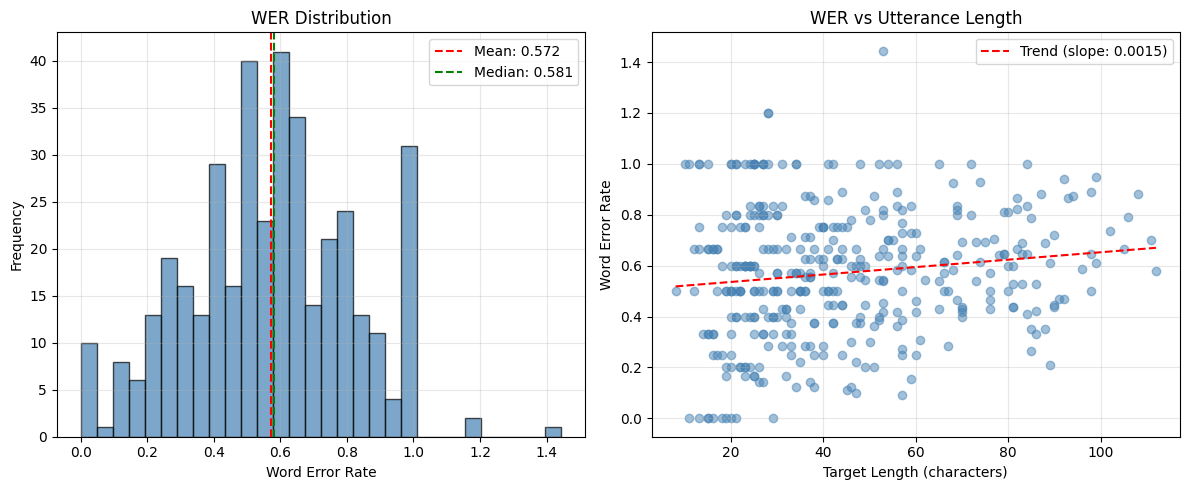

2026-11-25 15:49:28 | [5_111153] | INFO | 
💾 Test summary saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/test_summary_step_3000.json


INFO:Awingi-ASR-awingi_xlsr_v1:
💾 Test summary saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/test_summary_step_3000.json


2026-11-25 15:49:28 | [5_111153] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-11-25 15:49:28 | [5_111153] | INFO | ✅ TESTING COMPLETE


INFO:Awingi-ASR-awingi_xlsr_v1:✅ TESTING COMPLETE


... (8 outputs left out)

2026-11-25 15:49:28 | [5_111153] | INFO | 📊 Mean Utterance WER: 0.5716


INFO:Awingi-ASR-awingi_xlsr_v1:📊 Mean Utterance WER: 0.5716


2026-11-25 15:49:28 | [5_111153] | INFO | 📁 Results saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1


INFO:Awingi-ASR-awingi_xlsr_v1:📁 Results saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1


In [ ]:
# @title
# Cell 15: Model Testing & Evaluation (Audited Version)

import os
import glob
import json
import random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import Levenshtein

from pathlib import Path
from tqdm import tqdm
from tabulate import tabulate
from transformers import Wav2Vec2ForCTC
from evaluate import load
from jiwer import cer


# ============================================================
# 1. LOAD THE BEST CHECKPOINT
# ============================================================

def load_best_model(model_dir, processor, device):

    drive_logger.logger.info("=" * 60)
    drive_logger.logger.info("🔍 LOADING BEST MODEL FOR TESTING")
    drive_logger.logger.info("=" * 60)

    checkpoints = glob.glob(
        os.path.join(str(model_dir), "checkpoint-*")
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No checkpoints found in {model_dir}"
        )

    checkpoint_states = []

    for checkpoint in checkpoints:

        state_path = os.path.join(
            checkpoint, "trainer_state.json"
        )

        if not os.path.exists(state_path):
            continue

        try:
            with open(state_path, "r") as f:
                state = json.load(f)

            checkpoint_states.append({
                "checkpoint": checkpoint,
                "state": state
            })

        except Exception as e:
            drive_logger.logger.warning(
                f"Could not read {state_path}: {e}"
            )

    if not checkpoint_states:
        raise RuntimeError(
            "No valid trainer_state.json files found."
        )

    # The latest trainer state records the selected best checkpoint.
    latest_record = max(
        checkpoint_states,
        key=lambda x: x["state"].get("global_step", 0)
    )

    latest_state = latest_record["state"]

    best_checkpoint = latest_state.get(
        "best_model_checkpoint"
    )

    best_wer = latest_state.get("best_metric")

    # Resolve the recorded checkpoint path.
    if best_checkpoint:

        best_checkpoint = os.path.expanduser(
            best_checkpoint
        )

        if not os.path.exists(best_checkpoint):

            checkpoint_name = os.path.basename(
                best_checkpoint.rstrip("/")
            )

            matching = [
                cp for cp in checkpoints
                if os.path.basename(cp) == checkpoint_name
            ]

            if matching:
                best_checkpoint = matching[0]

    # Fallback if best_model_checkpoint is unavailable.
    if not best_checkpoint or not os.path.exists(best_checkpoint):

        valid_records = [
            item for item in checkpoint_states
            if item["state"].get("best_metric") is not None
        ]

        if not valid_records:
            raise RuntimeError(
                "Could not identify the best checkpoint."
            )

        selected_record = min(
            valid_records,
            key=lambda x: x["state"]["best_metric"]
        )

        best_checkpoint = selected_record["checkpoint"]
        best_wer = selected_record["state"]["best_metric"]

        drive_logger.logger.warning(
            "Using fallback checkpoint selection."
        )

    # Get actual step from checkpoint directory name.
    checkpoint_name = os.path.basename(
        best_checkpoint.rstrip("/")
    )

    try:
        best_step = int(
            checkpoint_name.replace("checkpoint-", "")
        )
    except ValueError:
        best_step = latest_state.get("global_step", "N/A")

    best_metrics = {
        "step": best_step,
        "epoch": latest_state.get("epoch", "N/A"),
        "wer": best_wer
    }

    drive_logger.logger.info("\n✅ Best checkpoint selected:")
    drive_logger.logger.info(f"   • Path: {best_checkpoint}")
    drive_logger.logger.info(f"   • Step: {best_metrics['step']}")
    drive_logger.logger.info(f"   • Validation WER: {best_metrics['wer']}")

    # Load model.
    model = Wav2Vec2ForCTC.from_pretrained(
        best_checkpoint
    ).to(device)

    # CRITICAL: Disable dropout and use evaluation behavior.
    model.eval()

    drive_logger.logger.info(
        "✅ Model loaded and switched to evaluation mode."
    )

    return model, best_checkpoint, best_metrics


# ============================================================
# 2. TRANSCRIBE ONE AUDIO FILE
# ============================================================

def transcribe_audio(model, processor, audio_path, device):

    try:

        audio, sr = sf.read(audio_path)

        # Convert stereo/multichannel audio to mono.
        if audio.ndim > 1:
            audio = audio.mean(axis=-1)

        audio = np.asarray(audio, dtype=np.float32)

        # Resample to 16 kHz when necessary.
        if sr != 16000:

            import torchaudio

            audio_tensor = torch.from_numpy(audio)

            audio = torchaudio.functional.resample(
                audio_tensor,
                orig_freq=sr,
                new_freq=16000
            ).numpy()

        # Feature extraction.
        inputs = processor(
            audio,
            sampling_rate=16000,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # Deterministic inference.
        model.eval()

        with torch.inference_mode():

            logits = model(**inputs).logits

            predicted_ids = torch.argmax(
                logits,
                dim=-1
            )

        transcription = processor.batch_decode(
            predicted_ids
        )[0]

        return transcription

    except Exception as e:

        drive_logger.logger.error(
            f"❌ Error transcribing {audio_path}: {e}"
        )

        return None


# ============================================================
# 3. TEST MODEL ON DATASET SPLIT
# ============================================================

def test_model_on_split(
    model,
    processor,
    test_df,
    device,
    num_samples=None,
    random_seed=42
):

    drive_logger.logger.info("\n" + "=" * 60)
    drive_logger.logger.info("📊 DETAILED MODEL TESTING")
    drive_logger.logger.info("=" * 60)

    # Check required columns.
    required_columns = ["path", "sentence"]

    for column in required_columns:
        if column not in test_df.columns:
            raise ValueError(
                f"Missing required column: {column}"
            )

    # Copy dataframe to avoid modifying original.
    test_df = test_df.copy()

    # Optional sampling.
    if num_samples and num_samples < len(test_df):

        test_df = test_df.sample(
            n=num_samples,
            random_state=random_seed
        )

        drive_logger.logger.info(
            f"🎲 Testing {num_samples} random samples "
            f"(seed={random_seed})"
        )

    else:

        drive_logger.logger.info(
            f"📊 Testing all {len(test_df)} samples"
        )

    # Load WER metric once.
    wer_metric = load("wer")

    results = []
    errors = []

    # Ensure evaluation mode throughout testing.
    model.eval()

    for idx, row in tqdm(
        test_df.iterrows(),
        total=len(test_df),
        desc="Testing"
    ):

        audio_path = row["path"]

        target = str(row["sentence"])

        prediction = transcribe_audio(
            model,
            processor,
            audio_path,
            device
        )

        if prediction is None:
            errors.append(audio_path)
            continue

        # Individual utterance WER.
        utterance_wer = wer_metric.compute(
            predictions=[prediction],
            references=[target]
        )

        # Character edit distance.
        char_distance = Levenshtein.distance(
            target,
            prediction
        )

        # Character accuracy defined as 1 - utterance CER.
        # This can be negative if errors exceed reference length.
        char_acc = (
            1 - char_distance / len(target)
            if len(target) > 0
            else (1.0 if len(prediction) == 0 else 0.0)
        )

        results.append({

            "audio_path": audio_path,
            "target": target,
            "prediction": prediction,
            "wer": utterance_wer,
            "char_acc": char_acc,
            "char_distance": char_distance,
            "target_len": len(target),
            "pred_len": len(prediction)

        })

    results_df = pd.DataFrame(results)

    if len(results_df) == 0:

        drive_logger.logger.error(
            "❌ No valid results obtained!"
        )

        return None

    # ========================================================
    # 4. CALCULATE OVERALL METRICS
    # ========================================================

    references = results_df["target"].tolist()
    predictions = results_df["prediction"].tolist()

    # Mean utterance WER.
    avg_wer = results_df["wer"].mean()

    # Median utterance WER.
    median_wer = results_df["wer"].median()

    # Standard corpus-level WER.
    corpus_wer = wer_metric.compute(
        predictions=predictions,
        references=references
    )

    # Standard corpus-level CER.
    corpus_cer = cer(
        references,
        predictions
    )

    # Character accuracy derived from corpus CER.
    corpus_char_accuracy = 1 - corpus_cer

    avg_char_acc = results_df["char_acc"].mean()

    std_wer = results_df["wer"].std()

    # ========================================================
    # 5. DISPLAY OVERALL METRICS
    # ========================================================

    drive_logger.logger.info("\n" + "=" * 60)
    drive_logger.logger.info("📈 OVERALL TEST METRICS")
    drive_logger.logger.info("=" * 60)

    drive_logger.logger.info(
        f"   • Samples tested: {len(results_df)}"
    )

    drive_logger.logger.info(
        f"   • Failed samples: {len(errors)}"
    )

    drive_logger.logger.info(
        f"   • Mean Utterance WER: {avg_wer:.4f}"
    )

    drive_logger.logger.info(
        f"   • Median Utterance WER: {median_wer:.4f}"
    )

    drive_logger.logger.info(
        f"   • Corpus-level WER: {corpus_wer:.4f}"
    )

    drive_logger.logger.info(
        f"   • Corpus-level CER: {corpus_cer:.4f}"
    )

    drive_logger.logger.info(
        f"   • Character Accuracy (1-CER): "
        f"{corpus_char_accuracy:.4f}"
    )

    drive_logger.logger.info(
        f"   • Mean Utterance Character Accuracy: "
        f"{avg_char_acc:.4f}"
    )

    # ========================================================
    # 6. BEST AND WORST PREDICTIONS
    # ========================================================

    best_idx = results_df["wer"].idxmin()
    worst_idx = results_df["wer"].idxmax()

    drive_logger.logger.info("\n" + "=" * 60)
    drive_logger.logger.info("🏆 BEST PREDICTION (Lowest WER)")
    drive_logger.logger.info("=" * 60)

    drive_logger.logger.info(
        f"   WER: {results_df.loc[best_idx, 'wer']:.4f}"
    )

    drive_logger.logger.info(
        f"   Target: {results_df.loc[best_idx, 'target']}"
    )

    drive_logger.logger.info(
        f"   Prediction: "
        f"{results_df.loc[best_idx, 'prediction']}"
    )

    drive_logger.logger.info("\n" + "=" * 60)
    drive_logger.logger.info("📉 WORST PREDICTION (Highest WER)")
    drive_logger.logger.info("=" * 60)

    drive_logger.logger.info(
        f"   WER: {results_df.loc[worst_idx, 'wer']:.4f}"
    )

    drive_logger.logger.info(
        f"   Target: {results_df.loc[worst_idx, 'target']}"
    )

    drive_logger.logger.info(
        f"   Prediction: "
        f"{results_df.loc[worst_idx, 'prediction']}"
    )

    # ========================================================
    # 7. ERROR ANALYSIS BY UTTERANCE LENGTH
    # ========================================================

    drive_logger.logger.info("\n" + "=" * 60)
    drive_logger.logger.info(
        "📊 ERROR ANALYSIS BY UTTERANCE LENGTH"
    )
    drive_logger.logger.info("=" * 60)

    bins = [
        0, 20, 40, 60, 80, 100, float("inf")
    ]

    labels = [
        "0-20", "21-40", "41-60",
        "61-80", "81-100", "100+"
    ]

    results_df["length_bin"] = pd.cut(
        results_df["target_len"],
        bins=bins,
        labels=labels
    )

    length_stats = results_df.groupby(
        "length_bin",
        observed=False
    ).agg({
        "wer": ["mean", "count"]
    }).round(4)

    drive_logger.logger.info(
        "\n" + tabulate(
            length_stats,
            headers=["Length", "Avg WER", "Count"],
            tablefmt="grid"
        )
    )

    # ========================================================
    # 8. SAVE DETAILED RESULTS
    # ========================================================

    save_path = (
        drive_logger.exp_dir /
        f"test_results_step_{best_metrics['step']}.csv"
    )

    results_df.to_csv(
        save_path,
        index=False
    )

    drive_logger.logger.info(
        f"\n💾 Detailed results saved to: {save_path}"
    )

    # Keep calculated metrics available for the summary.
    results_df.attrs["corpus_wer"] = float(corpus_wer)
    results_df.attrs["corpus_cer"] = float(corpus_cer)
    results_df.attrs["corpus_char_accuracy"] = float(
        corpus_char_accuracy
    )
    results_df.attrs["avg_wer"] = float(avg_wer)
    results_df.attrs["median_wer"] = float(median_wer)
    results_df.attrs["std_wer"] = (
        float(std_wer) if pd.notna(std_wer) else None
    )
    results_df.attrs["avg_char_acc"] = float(avg_char_acc)
    results_df.attrs["failed_samples"] = len(errors)

    return results_df


# ============================================================
# 9. DISPLAY SAMPLE PREDICTIONS
# ============================================================

def show_sample_predictions(
    model,
    processor,
    test_df,
    device,
    num_examples=10
):

    drive_logger.logger.info("\n" + "=" * 80)
    drive_logger.logger.info("📋 SAMPLE PREDICTIONS")
    drive_logger.logger.info("=" * 80)

    model.eval()

    samples = test_df.sample(
        n=min(num_examples, len(test_df)),
        random_state=42
    )

    table_data = []

    for idx, row in samples.iterrows():

        prediction = transcribe_audio(
            model,
            processor,
            row["path"],
            device
        )

        target = str(row["sentence"])

        exact_match = (
            "✅" if prediction == target else "❌"
        )

        if prediction is not None:

            distance = Levenshtein.distance(
                target,
                prediction
            )

            similarity = (
                1 - distance / max(len(target), len(prediction), 1)
            )

        else:

            prediction = "[ERROR]"
            similarity = 0

        table_data.append([

            idx,

            target[:50] + "..."
            if len(target) > 50 else target,

            prediction[:50] + "..."
            if len(prediction) > 50 else prediction,

            exact_match,

            f"{similarity:.2f}"

        ])

    headers = [
        "#", "Target", "Prediction",
        "Match", "Similarity"
    ]

    print(
        tabulate(
            table_data,
            headers=headers,
            tablefmt="grid"
        )
    )

    return table_data


# ============================================================
# 10. PLOT ERROR DISTRIBUTION
# ============================================================

def plot_error_distribution(results_df, save_path=None):

    try:

        plt.figure(figsize=(12, 5))

        # WER distribution.
        plt.subplot(1, 2, 1)

        plt.hist(
            results_df["wer"],
            bins=30,
            edgecolor="black",
            alpha=0.7,
            color="steelblue"
        )

        plt.axvline(
            results_df["wer"].mean(),
            color="red",
            linestyle="--",
            label=f"Mean: {results_df['wer'].mean():.3f}"
        )

        plt.axvline(
            results_df["wer"].median(),
            color="green",
            linestyle="--",
            label=f"Median: {results_df['wer'].median():.3f}"
        )

        plt.xlabel("Word Error Rate")
        plt.ylabel("Frequency")
        plt.title("WER Distribution")
        plt.legend()
        plt.grid(True, alpha=0.3)

        # WER versus target length.
        plt.subplot(1, 2, 2)

        plt.scatter(
            results_df["target_len"],
            results_df["wer"],
            alpha=0.5,
            color="steelblue"
        )

        plt.xlabel("Target Length (characters)")
        plt.ylabel("Word Error Rate")
        plt.title("WER vs Utterance Length")
        plt.grid(True, alpha=0.3)

        # Trend line.
        if len(results_df) > 1:

            x = results_df["target_len"].to_numpy()
            y = results_df["wer"].to_numpy()

            z = np.polyfit(x, y, 1)
            p = np.poly1d(z)

            plt.plot(
                sorted(x),
                p(sorted(x)),
                "r--",
                label=f"Trend (slope: {z[0]:.4f})"
            )

            plt.legend()

        plt.tight_layout()

        if save_path:

            plt.savefig(
                save_path,
                dpi=150,
                bbox_inches="tight"
            )

            drive_logger.logger.info(
                f"📊 Plot saved to: {save_path}"
            )

        plt.show()
        plt.close()

    except Exception as e:

        drive_logger.logger.warning(
            f"⚠️ Could not generate plots: {e}"
        )


# ============================================================
# 11. MAIN TESTING EXECUTION
# ============================================================

drive_logger.logger.info("\n" + "=" * 70)
drive_logger.logger.info("🚀 STARTING MODEL TESTING")
drive_logger.logger.info("=" * 70)

# Load test dataset if it is not already available.
if "test_df" not in globals():

    test_df = pd.read_csv(TEST_CSV)

    drive_logger.logger.info(
        f"✅ Loaded test set: {len(test_df)} samples"
    )

# Check dataset size.
drive_logger.logger.info(
    f"Test dataset size: {len(test_df)}"
)

# Device.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

drive_logger.logger.info(
    f"🖥 Using device: {device}"
)

# Model directory.
MODEL_DIR = WORK_DIR / "xlsr_awingi_extended_v1"

# Load best model.
model, checkpoint_path, best_metrics = load_best_model(
    MODEL_DIR,
    processor,
    device
)

# Test configuration.
TEST_ALL_SAMPLES = True

NUM_SAMPLES = (
    None if TEST_ALL_SAMPLES else 50
)

# Run comprehensive testing.
results_df = test_model_on_split(
    model=model,
    processor=processor,
    test_df=test_df,
    device=device,
    num_samples=NUM_SAMPLES,
    random_seed=42
)

if results_df is not None:

    # ========================================================
    # SAMPLE PREDICTIONS
    # ========================================================

    show_sample_predictions(
        model=model,
        processor=processor,
        test_df=test_df,
        device=device,
        num_examples=15
    )

    # ========================================================
    # ERROR DISTRIBUTION PLOT
    # ========================================================

    plot_path = (
        drive_logger.exp_dir /
        f"error_analysis_step_{best_metrics['step']}.png"
    )

    plot_error_distribution(
        results_df,
        save_path=plot_path
    )

    # ========================================================
    # SAVE SUMMARY
    # ========================================================

    summary = {

        "model_path": checkpoint_path,

        "step": best_metrics["step"],

        "epoch": best_metrics["epoch"],

        "validation_wer": best_metrics["wer"],

        "test_metrics": {

            "corpus_wer": results_df.attrs["corpus_wer"],

            "corpus_cer": results_df.attrs["corpus_cer"],

            "corpus_character_accuracy":
                results_df.attrs["corpus_char_accuracy"],

            "avg_utterance_wer":
                results_df.attrs["avg_wer"],

            "median_utterance_wer":
                results_df.attrs["median_wer"],

            "std_utterance_wer":
                results_df.attrs["std_wer"],

            "avg_utterance_char_accuracy":
                results_df.attrs["avg_char_acc"],

            "samples_tested": len(results_df),

            "failed_samples":
                results_df.attrs["failed_samples"]

        }

    }

    summary_path = (
        drive_logger.exp_dir /
        f"test_summary_step_{best_metrics['step']}.json"
    )

    with open(summary_path, "w") as f:

        json.dump(
            summary,
            f,
            indent=2
        )

    drive_logger.logger.info(
        f"\n💾 Test summary saved to: {summary_path}"
    )

    # ========================================================
    # FINAL OUTPUT
    # ========================================================

    drive_logger.logger.info("\n" + "=" * 70)
    drive_logger.logger.info("✅ TESTING COMPLETE")
    drive_logger.logger.info("=" * 70)

    drive_logger.logger.info(
        f"📊 Final Corpus WER: "
        f"{summary['test_metrics']['corpus_wer']:.4f}"
    )

    drive_logger.logger.info(
        f"📊 Final Corpus CER: "
        f"{summary['test_metrics']['corpus_cer']:.4f}"
    )

    drive_logger.logger.info(
        f"📊 Character Accuracy (1-CER): "
        f"{summary['test_metrics']['corpus_character_accuracy']:.4f}"
    )

    drive_logger.logger.info(
        f"📊 Mean Utterance WER: "
        f"{summary['test_metrics']['avg_utterance_wer']:.4f}"
    )

    drive_logger.logger.info(
        f"📁 Results saved to: {drive_logger.exp_dir}"
    )